# Milestone 2: Pricing the Unicorn
### Robust Mahalanobis detection of athletic outliers in the NFL Draft, 2000–2026

**Question.** Some draft prospects have bodies and workouts unlike anyone else at their position.
Teams call them *unicorns*. When a team spends a pick on one, does it get its money's worth?

**Approach.** This notebook rebuilds every analysis in the paper from the raw data, in five parts:

1. **Data**: combine measurements, draft picks and career value from nflverse.
2. **Features**: size- and era-adjusted drill scores, computed within each position.
3. **Detection (primary method)**: a *robust Mahalanobis distance* measures how far each prospect's
   profile sits from the normal range for his position. The top 5% are flagged as unicorns, then typed as
   **Freak**, **Odd build** or **Red flag** by whether they tested better or worse than their size predicts.
4. **Value**: each drafted player's career Approximate Value (AV) is compared with what his draft slot
   should have returned, and graded **Bust**, **Good value** or **Steal**.
5. **Analysis**: what the market pays for unicorns, what it gets back, and how that varies by round,
   position, body type and team, with robustness checks.

## 1. Setup
Libraries used: **pandas/numpy** for data, **scikit-learn** for imputation, the robust covariance
estimator, PCA and k-means, **statsmodels** for regressions and smoothing, **scipy** for tests,
**matplotlib** for charts. All are pre-installed in Colab.

In [3]:
import sys
import zipfile
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from scipy.stats import rankdata, chi2
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (unlocks IterativeImputer)
from sklearn.impute import IterativeImputer
from sklearn.covariance import MinCovDet
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.0f}" if float(x).is_integer() and abs(x) >= 1 else f"{x:,.3f}")

# ---- analysis settings (change here, everything downstream follows) ----
SEED = 42                 # fixes every random step so results reproduce exactly
UNICORN_SHARE = 0.05      # top 5% of Mahalanobis scores within each position = unicorns
ATHLETIC_CUT = 0.75       # athleticism composite (SD) that separates Freak / Odd build / Red flag
MCD_SUPPORT = 0.85        # share of players the robust covariance is fitted on
MIN_DRILL_COVERAGE = 0.25 # a drill is skipped for a position if <25% of prospects did it (e.g. QB bench)
MATURE_LAST = 2015        # draft classes used to fit the slot-value curve (careers essentially complete)
LAST_GRADED = 2022        # last draft class graded (needs ≥ 4 seasons)
N_BOOT = 4000             # bootstrap resamples for confidence intervals
RNG = np.random.default_rng(SEED)

# ---- chart style ----
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10.5, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "axes.axisbelow": True, "legend.frameon": False})
TYPE_ORDER = ["Freak", "Odd build", "Red flag", "Typical"]
TYPE_COLOR = {"Freak": "#E69F00", "Odd build": "#7B5EA7", "Red flag": "#D1495B", "Typical": "#9AA3AD"}
GRADE_COLOR = {"Bust": "#D1495B", "Good value": "#8FA3B8", "Steal": "#2A9D8F"}
POSITIONS = ["QB", "RB", "WR", "TE", "OT", "IOL", "DT", "EDGE", "LB", "CB", "S"]

### Load the source data
**Sources.** All three files come from the open **nflverse** project, which redistributes
Pro-Football-Reference tables (github.com/nflverse/nflverse-data, releases `combine`, `draft_picks`, `players`):

| File | Contents |
|---|---|
| `combine.csv` | Every combine prospect 2000–2026: height, weight, 40-yard dash, bench, vertical, broad jump, 3-cone, shuttle, and draft slot |
| `draft_picks.csv` | Every draft pick since 1980 with career weighted Approximate Value (AV), games, starts, Pro Bowls |
| `players.csv` | NFL roster positions, used to resolve generic combine labels (OL, DL, DB) |

nflverse updates these files during the season, so we use the **October 2026 snapshot** stored in the
replication zip. The checksums below confirm the files are exactly the ones the paper used.

In [4]:
SNAPSHOT_SHA256 = {
    "combine.csv": "5648886b1bb9de8a0c42b05ee7b1d9cbe58897676caaa2f6a4a3d3c9228235bb",
    "draft_picks.csv": "769633acc15f9539cf3e57a8ed2bf95c6392b038e765cef60a4542d6da3a03f8",
    "players.csv": "7ea1f10f0c3b0bf5c026a4b5935c6d01e4a72864a3122594a6df493b5bf29d97",
}

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Pricing the Unicorn")
    DATA = Path("/content/data")
    DATA.mkdir(exist_ok=True)
    with zipfile.ZipFile(PROJECT / "unicorn_replication_package.zip") as archive:
        for name in SNAPSHOT_SHA256:
            (DATA / name).write_bytes(archive.read(f"data/{name}"))
    OUT = PROJECT / "milestone2_outputs"
else:  # running locally: expects a data/ folder next to the notebook
    DATA = Path("data")
    OUT = Path("milestone2_outputs")
OUT.mkdir(exist_ok=True)

for name, expected in SNAPSHOT_SHA256.items():
    actual = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    assert actual == expected, f"{name} is not the October 2026 snapshot"
print("All three source files verified.")

combine = pd.read_csv(DATA / "combine.csv")
draft = pd.read_csv(DATA / "draft_picks.csv")
players = pd.read_csv(DATA / "players.csv", low_memory=False)
display(pd.DataFrame({"rows": [len(combine), len(draft), len(players)],
                      "columns": [combine.shape[1], draft.shape[1], players.shape[1]]},
                     index=["combine", "draft_picks", "players"]))
display(combine[["season", "player_name", "pos", "school", "ht", "wt", "forty", "vertical", "draft_ovr"]].head())

Mounted at /content/drive
All three source files verified.


,rows,columns
combine,8968,18
draft_picks,12927,36
players,24844,39


,season,player_name,pos,school,ht,wt,forty,vertical,draft_ovr
0,2000,John Abraham,OLB,South Carolina,6-4,252,4.550,NaN,13
1,2000,Shaun Alexander,RB,Alabama,6-0,218,4.580,NaN,19
2,2000,Darnell Alford,OT,Boston Col.,6-4,334,5.560,25,188
3,2000,Kyle Allamon,TE,Texas Tech,6-2,253,4.970,29,NaN
4,2000,Rashard Anderson,CB,Jackson State,6-2,206,4.550,34,23


## 2. Build the modelling sample
Steps, each logged below:
1. Convert height from `"6-4"` to inches.
2. The combine file has no draft slots for 2026 yet, so 2026 prospects are matched to the draft file by exact name.
3. Attach each drafted player's career AV by (draft year, overall pick), and his NFL roster position.
4. **Namesakes**: the source occasionally gives one draft pick to two same-named prospects. We keep the one whose
   position family matches the drafted position.
5. Assign 11 position groups (generic labels such as `OL` are resolved with the roster position, then by size).
6. Require a measured height, weight and 40-yard dash. Other drills may be missing; they are imputed later.
7. **Data errors**: a handful of rows have a size impossible for their position (a 195-lb "offensive lineman").
   Linemen under 270 lb and linebackers outside 210–275 lb are removed.

In [5]:
def height_to_inches(value):
    """'6-4' -> 76.0; anything unreadable -> NaN."""
    try:
        feet, inches = str(value).split("-")
        return 12 * int(feet) + int(inches)
    except ValueError:
        return np.nan


def position_group(row):
    """Map a combine position to one of 11 groups, using NFL roster position for generic labels."""
    pos, ht, wt = row["pos"], row["ht"], row["wt"]
    roster = row["nfl_pos"] if isinstance(row["nfl_pos"], str) else row["draft_pos"]
    direct = {"QB": "QB", "RB": "RB", "WR": "WR", "TE": "TE", "OT": "OT", "OG": "IOL", "G": "IOL", "C": "IOL",
              "DT": "DT", "DE": "EDGE", "EDGE": "EDGE", "ILB": "LB", "LB": "LB", "CB": "CB", "S": "S", "SAF": "S"}
    if pos in direct:
        return direct[pos]
    if pos == "OL":
        if roster in ("T", "OT"): return "OT"
        if roster in ("G", "C"): return "IOL"
        return "OT" if ht >= 77 else "IOL"
    if pos == "DL":
        if roster in ("DT", "NT"): return "DT"
        if roster in ("DE", "OLB", "LB"): return "EDGE"
        return "DT" if wt >= 285 else "EDGE"
    if pos == "OLB":
        return "EDGE" if wt >= 245 else "LB"
    if pos == "DB":
        if roster == "CB": return "CB"
        if roster in ("S", "SAF", "FS", "SS"): return "S"
        return "S" if wt >= 200 else "CB"
    return None  # kickers, punters, long snappers, fullbacks


POSITION_FAMILY = {**dict.fromkeys(["QB", "RB", "FB", "WR", "TE"], "O"),
                   **dict.fromkeys(["T", "OT", "G", "OG", "C", "OL"], "OL"),
                   **dict.fromkeys(["DT", "NT", "DE", "DL", "EDGE", "LB", "OLB", "ILB"], "F7"),
                   **dict.fromkeys(["CB", "DB", "S", "SAF", "FS", "SS"], "DB")}
RELOCATED = {"STL": "LAR", "SDG": "LAC", "OAK": "LVR"}

In [6]:
log = []
df = combine.copy()
df["ht"] = df["ht"].map(height_to_inches)
log.append(("Combine records, 2000–2026", len(df)))

# 2026 draft slots by exact name
picks_2026 = draft[draft.season.eq(2026)].drop_duplicates("pfr_player_name").set_index("pfr_player_name")
is_2026 = df.season.eq(2026) & df.player_name.isin(picks_2026.index)
df.loc[is_2026, "draft_year"] = 2026
df.loc[is_2026, "draft_round"] = df.loc[is_2026, "player_name"].map(picks_2026["round"])
df.loc[is_2026, "draft_ovr"] = df.loc[is_2026, "player_name"].map(picks_2026["pick"])
print(f"2026 prospects matched to a pick by name: {is_2026.sum()}")

# career outcomes and roster positions
outcomes = (draft[draft.season.ge(2000)][["season", "pick", "team", "position", "w_av"]]
            .rename(columns={"season": "draft_year", "pick": "draft_ovr", "position": "draft_pos"}))
df = df.merge(outcomes, on=["draft_year", "draft_ovr"], how="left", validate="many_to_one")
roster = players[["pfr_id", "position"]].dropna().drop_duplicates("pfr_id").rename(columns={"position": "nfl_pos"})
df = df.merge(roster, on="pfr_id", how="left", validate="many_to_one")

# namesakes: one pick, two prospects -> keep the position match
shared_pick = df.draft_ovr.notna() & df.duplicated(["draft_year", "draft_ovr"], keep=False)
df["_match"] = df.pos.map(POSITION_FAMILY).eq(df.draft_pos.map(POSITION_FAMILY)).astype(int)
keep = (df[shared_pick].sort_values("_match", ascending=False, kind="stable")
        .drop_duplicates(["draft_year", "draft_ovr"]).index)
df = df[~shared_pick | df.index.isin(keep)].drop(columns="_match")
log.append(("Drop namesakes sharing one draft pick", len(df)))

df["grp"] = df.apply(position_group, axis=1)
df = df[df.grp.notna()]
log.append(("Keep the 11 position groups", len(df)))

df = df.dropna(subset=["ht", "wt", "forty"])
log.append(("Require height, weight and 40 time", len(df)))

impossible = (df.grp.isin(["OT", "IOL"]) & df.wt.lt(270)) | (df.grp.eq("LB") & ~df.wt.between(210, 275))
data_errors = df[impossible][["player_name", "season", "pos", "grp", "ht", "wt", "forty"]]
df = df[~impossible].copy().reset_index(drop=True)
df["pid"] = np.arange(len(df))  # stable prospect id
log.append(("Remove sizes impossible for the position", len(df)))

df["drafted"] = df.draft_ovr.notna()
df["franchise"] = df.team.replace(RELOCATED)
DRILLS = ["forty", "bench", "vertical", "broad_jump", "cone", "shuttle"]
df["n_drills"] = df[DRILLS].notna().sum(axis=1)

sample_log = pd.DataFrame(log, columns=["Step", "Rows remaining"])
sample_log["Removed"] = (-sample_log["Rows remaining"].diff()).fillna(0).astype(int)
display(sample_log)
display(Markdown("**Rows removed as data errors:**"))
display(data_errors)

2026 prospects matched to a pick by name: 211


,Step,Rows remaining,Removed
0,"Combine records, 2000–2026",8968,0
1,Drop namesakes sharing one draft pick,8958,10
2,Keep the 11 position groups,8528,430
3,"Require height, weight and 40 time",7699,829
4,Remove sizes impossible for the position,7690,9


**Rows removed as data errors:**

,player_name,season,pos,grp,ht,wt,forty
841,Ben Miller,2002,C,IOL,74,263,4.920
1311,Josh Buhl,2004,OLB,LB,71,204,4.730
6615,Nick Coe,2020,LB,LB,77,280,4.890
6973,Tyler Coyle,2021,LB,LB,73,209,4.380
7048,Noah Hannon,2021,OL,IOL,72,238,5.150
7205,Jarrett Patterson,2021,OL,IOL,66,195,4.520
7263,DAnte Smith,2021,LB,LB,77,305,5.290
7331,Jarell White,2021,LB,LB,68,202,4.580
7339,Carson Williams,2021,OL,IOL,76,254,4.790


### What the sample looks like
Body size differs enormously across positions, which is why every later step is done *within* a position group.
Missing drills are common, and skipping a drill is often a choice: quarterbacks almost never bench press.

,prospects,drafted,mean_ht,mean_wt,mean_forty,mean_drills
grp,,,,,,
QB,413,239,74.690,222.180,4.810,4.350
RB,716,424,70.420,213.120,4.550,4.470
WR,1156,708,72.740,201.010,4.510,4.360
TE,452,299,76.290,252.950,4.760,4.740
OT,608,440,77.640,315.400,5.230,4.760
IOL,722,433,75.820,311.020,5.260,4.860
DT,604,431,74.960,306.740,5.090,4.590
EDGE,826,604,75.520,263.240,4.780,4.660
LB,718,483,73.410,237.120,4.690,4.630


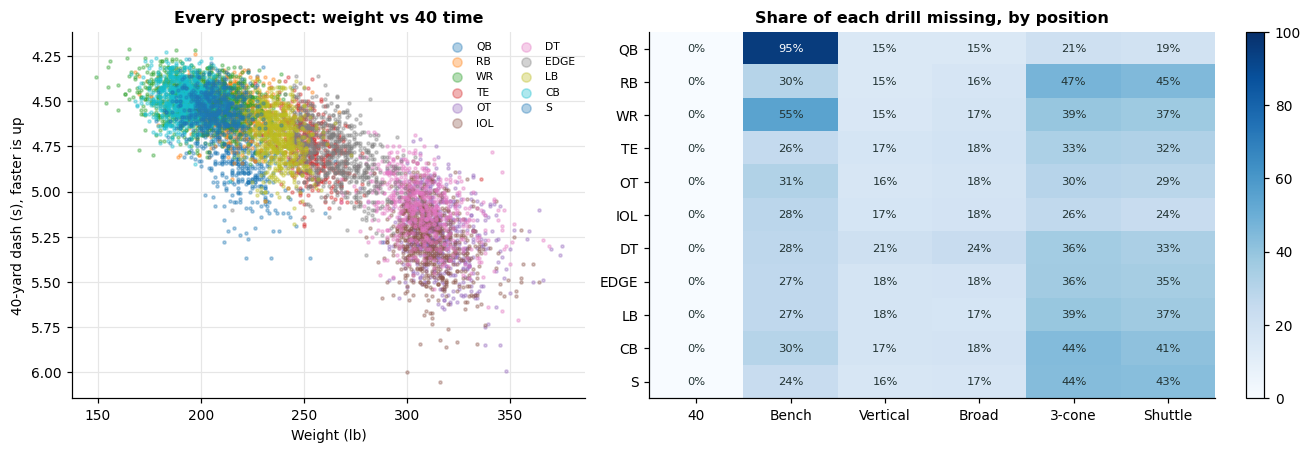

Modelling sample: 7,690 prospects, 5,081 drafted; 23.7% of drill results missing


In [7]:
census = df.groupby("grp").agg(prospects=("player_name", "size"), drafted=("drafted", "sum"),
                               mean_ht=("ht", "mean"), mean_wt=("wt", "mean"), mean_forty=("forty", "mean"),
                               mean_drills=("n_drills", "mean")).reindex(POSITIONS)
display(census.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
for g in POSITIONS:
    s = df[df.grp == g]
    axes[0].scatter(s.wt, s.forty, s=4, alpha=.35, label=g)
axes[0].invert_yaxis()
axes[0].set(title="Every prospect: weight vs 40 time", xlabel="Weight (lb)", ylabel="40-yard dash (s), faster is up")
axes[0].legend(ncol=2, fontsize=7, markerscale=3)
missing = df.groupby("grp")[DRILLS].agg(lambda x: x.isna().mean() * 100).reindex(POSITIONS)
im = axes[1].imshow(missing, cmap="Blues", vmin=0, vmax=100, aspect="auto")
axes[1].set_xticks(range(6), ["40", "Bench", "Vertical", "Broad", "3-cone", "Shuttle"])
axes[1].set_yticks(range(11), POSITIONS)
axes[1].grid(False)
for i in range(11):
    for j in range(6):
        v = missing.iloc[i, j]
        axes[1].text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=7.5, color="white" if v > 55 else "#233")
axes[1].set_title("Share of each drill missing, by position")
plt.colorbar(im, ax=axes[1], fraction=.03)
plt.tight_layout()
plt.show()
print(f"Modelling sample: {len(df):,} prospects, {df.drafted.sum():,} drafted; "
      f"{df[DRILLS].isna().values.mean():.1%} of drill results missing")

## 3. Features: size- and era-adjusted drill scores
A 4.9-second 40 is slow for a receiver and remarkable for a nose tackle, and even within a position heavier players
run slower. So for each position and drill we fit a regression on players who actually ran it:

$$\text{drill} = \beta_0 + \beta_1\,\text{height} + \beta_2\,\text{weight} + \beta_3\,\text{weight}^2 + \beta_4\,\text{year} + \beta_5\,\mathbf{1}[\text{2021}] + \varepsilon$$

The residual says how much better or worse a player tested than his size and era predict. It is then scaled
**robustly** (median and MAD instead of mean and SD, so the outliers we are hunting don't distort the yardstick)
and flipped so that **positive always means better**. 2021 gets its own term because there was no combine that
year; its numbers are hand-timed pro-day results.

**Missing drills** are filled by iterative imputation within position (each drill predicted from the others).
Imputed values sit near the middle of the distribution, so imputation can only make a player look *less* unusual.

The **athleticism composite** (`ath_z`) is the average of a player's adjusted drill scores, standardized within position.

In [8]:
HIGHER_IS_BETTER = {"forty": False, "bench": True, "vertical": True, "broad_jump": True, "cone": False, "shuttle": False}


def robust_z(values, reference=None):
    """(x - median) / (1.4826 * MAD); the location and scale come from `reference` if given."""
    ref = values if reference is None else reference
    median = np.median(ref)
    mad = 1.4826 * np.median(np.abs(ref - median))
    return (values - median) / mad


def adjust_position(group):
    """Impute missing drills and return size/era-adjusted, oriented drill scores for one position group."""
    drills = [d for d in DRILLS if group[d].notna().mean() >= MIN_DRILL_COVERAGE]
    raw = group[["ht", "wt"] + drills]
    filled = pd.DataFrame(IterativeImputer(random_state=SEED, max_iter=25).fit_transform(raw),
                          columns=raw.columns, index=group.index)
    design = np.column_stack([np.ones(len(group)), filled.ht, filled.wt, filled.wt ** 2,
                              group.season - 2013, group.season.eq(2021).astype(float)])
    out = pd.DataFrame(index=group.index)
    out["z_ht"] = robust_z(filled.ht.values)
    out["z_wt"] = robust_z(filled.wt.values)
    for d in DRILLS:
        if d not in drills:
            out["adj_" + d] = np.nan
            continue
        measured = group[d].notna().values
        beta, *_ = np.linalg.lstsq(design[measured], filled[d].values[measured], rcond=None)
        residual = filled[d].values - design @ beta
        sign = 1 if HIGHER_IS_BETTER[d] else -1
        out["adj_" + d] = sign * robust_z(residual, residual[measured])
    athleticism = out[["adj_" + d for d in drills]].mean(axis=1)
    out["ath_z"] = (athleticism - athleticism.mean()) / athleticism.std()
    out["features"] = ",".join(["z_ht", "z_wt"] + ["adj_" + d for d in drills])
    return out


features = pd.concat([adjust_position(group) for _, group in df.groupby("grp")])
df = df.join(features)
ADJ = ["adj_" + d for d in DRILLS]
display(df[["player_name", "season", "grp", "ht", "wt", "forty", "z_ht", "z_wt", "adj_forty", "adj_vertical", "ath_z"]]
        .sort_values("adj_forty", ascending=False).head(8).round(2))

,player_name,season,grp,ht,wt,forty,z_ht,z_wt,adj_forty,adj_vertical,ath_z
3091,Bruce Campbell,2010,OT,78,314,4.750,0.000,0.100,3.200,1.220,1.790
1874,Vernon Davis,2006,TE,75,254,4.380,-0.670,0.220,3.160,2.870,3.450
3986,Terron Armstead,2013,OT,77,306,4.710,-0.670,-0.670,3.030,1.900,1.980
6673,Jordan Davis,2022,DT,78,341,4.780,2.020,2.620,2.960,1.730,3.080
851,Donte' Stallworth,2002,WR,72,197,4.220,-0.340,-0.250,2.940,0.970,1.860
1543,Elton Brown,2005,IOL,77,329,4.930,0.670,1.930,2.940,0.870,2.190
4105,Lane Johnson,2013,OT,78,303,4.720,0.000,-0.960,2.890,1.590,2.370
6501,Jayson Oweh,2021,EDGE,77,257,4.360,1.350,-0.340,2.880,1.970,2.700


## 4. Primary method: robust Mahalanobis distance
**Idea.** For each prospect we ask: *how far is this profile from the centre of his position group, measured in
units that respect how the measurements normally move together?* That is the Mahalanobis distance:

$$D^2(\mathbf{x}) = (\mathbf{x}-\boldsymbol\mu)^\top \boldsymbol\Sigma^{-1} (\mathbf{x}-\boldsymbol\mu)$$

Plain Euclidean distance would treat "fast" and "explosive" as independent surprises. They aren't: fast players
usually jump well. Dividing by the covariance $\boldsymbol\Sigma$ means that a player who is fast **but not**
explosive, or heavy **and** fast, gets a large distance. Unusual *combinations* are what make a unicorn.

**Why robust.** If $\boldsymbol\mu$ and $\boldsymbol\Sigma$ were ordinary means and covariances, the unicorns
themselves would stretch them and hide. The **Minimum Covariance Determinant** (MCD) estimator fits the centre and
shape on the tightest 85% of players only, so the outliers are measured against a clean "normal" range.

**Two views per position.**
- *Full workout*: height, weight and every adjusted drill (some imputed).
- *Size–speed*: height, weight and adjusted 40 only, all measured for everyone. This catches players such as
  Calvin Johnson, whose only recorded drill is the 40.

Each view's $D^2$ is turned into a percentile within the position. A player's **unicorn score** is the higher of
his two percentiles, re-ranked; the top 5% are **unicorns**. Under normality $D^2$ follows a $\chi^2$ distribution
with as many degrees of freedom as features, which gives a second, model-based cutoff we use as a robustness check.

In [9]:
def robust_mahalanobis(X):
    """Squared robust Mahalanobis distance of every row of X, plus the fitted MCD model."""
    mcd = MinCovDet(support_fraction=MCD_SUPPORT, random_state=SEED).fit(X)
    return mcd.mahalanobis(X), mcd


def percentile_rank(values):
    return rankdata(values) / len(values)


def biggest_driver(X, mcd, names):
    """Which feature contributes most to each player's distance: (x-μ)_j · [Σ⁻¹(x-μ)]_j."""
    centred = X - mcd.location_
    contribution = centred * (centred @ mcd.get_precision())
    return np.array(names)[contribution.argmax(axis=1)]


scores = []
for g, group in df.groupby("grp"):
    full_cols = group.features.iloc[0].split(",")
    views = {"full": full_cols, "core": ["z_ht", "z_wt", "adj_forty"]}
    s = pd.DataFrame(index=group.index)
    for view, cols in views.items():
        X = group[cols].values
        d2, mcd = robust_mahalanobis(X)
        s[f"d2_{view}"] = d2
        s[f"pct_{view}"] = percentile_rank(d2)
        s[f"chi2_p_{view}"] = chi2.sf(d2, df=len(cols))  # tail probability if profiles were multivariate normal
        if view == "full":
            s["driver"] = biggest_driver(X, mcd, cols)
    s["md_score"] = s[["pct_full", "pct_core"]].max(axis=1)
    s["md_pct"] = percentile_rank(s.md_score)
    scores.append(s)

df = df.join(pd.concat(scores))
df["unicorn"] = df.md_pct > 1 - UNICORN_SHARE


def unicorn_type(row):
    if not row.unicorn:
        return "Typical"
    if row.ath_z >= ATHLETIC_CUT:
        return "Freak"       # rare AND more athletic than his size predicts
    if row.ath_z <= -ATHLETIC_CUT:
        return "Red flag"    # rare because he tested far below his size peers
    return "Odd build"       # rare mainly through body dimensions or a mixed profile


df["utype"] = df.apply(unicorn_type, axis=1)
DRIVER_LABEL = {"z_ht": "Height", "z_wt": "Weight", "adj_forty": "40 speed", "adj_bench": "Bench",
                "adj_vertical": "Vertical", "adj_broad_jump": "Broad jump", "adj_cone": "3-cone", "adj_shuttle": "Shuttle"}
df["driver"] = df.driver.map(DRIVER_LABEL)

counts = pd.crosstab(df.grp, df.utype).reindex(index=POSITIONS, columns=TYPE_ORDER)
counts.loc["All"] = counts.sum()
display(counts)
print(f"{df.unicorn.sum()} unicorns: " + ", ".join(f"{(df.utype == t).sum()} {t}" for t in TYPE_ORDER[:3]))

utype,Freak,Odd build,Red flag,Typical
grp,,,,
QB,7,7,7,392
RB,5,14,18,679
WR,19,21,18,1098
TE,4,11,8,429
OT,6,13,12,577
IOL,9,14,13,686
DT,10,14,6,574
EDGE,14,12,15,785
LB,7,15,14,682


388 unicorns: 99 Freak, 151 Odd build, 138 Red flag


### Does the χ² assumption hold?
If profiles were multivariate normal, the robust $D^2$ would line up with the χ² line in a Q–Q plot. The tails bend
upward: real athletes produce more extreme profiles than a normal model expects. That is why we flag by **percentile
rank within position** (a fixed 5% per group) rather than a χ² p-value, and keep the χ² cutoff as a sensitivity check.

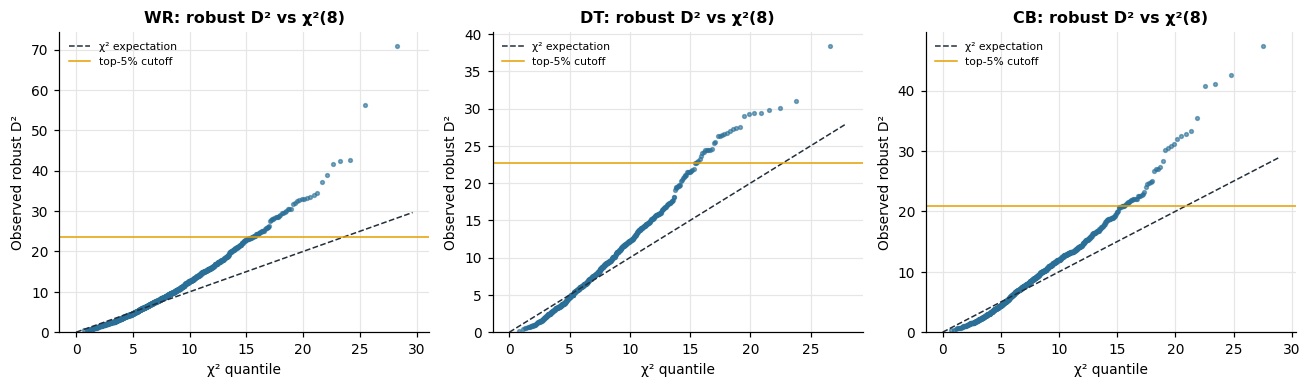

Share of prospects beyond the χ² 97.5% point (full view): 10.4%  (normal theory expects 2.5%)


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, g in zip(axes, ["WR", "DT", "CB"]):
    s = df[df.grp == g]
    k = len(s.features.iloc[0].split(","))
    observed = np.sort(s.d2_full.values)
    theoretical = chi2.ppf((np.arange(1, len(observed) + 1) - .5) / len(observed), df=k)
    ax.scatter(theoretical, observed, s=6, color="#2A6F97", alpha=.6)
    lim = theoretical.max() * 1.05
    ax.plot([0, lim], [0, lim], color="#22303C", lw=1, ls="--", label="χ² expectation")
    cut = np.quantile(observed, 1 - UNICORN_SHARE)
    ax.axhline(cut, color=TYPE_COLOR["Freak"], lw=1, label="top-5% cutoff")
    ax.set(title=f"{g}: robust D² vs χ²({k})", xlabel="χ² quantile", ylabel="Observed robust D²", ylim=(0, observed.max() * 1.05))
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
share_chi = (df.chi2_p_full < .025).mean()
print(f"Share of prospects beyond the χ² 97.5% point (full view): {share_chi:.1%}  (normal theory expects 2.5%)")

### Where the unicorns are
Weight vs 40 time for three positions. Grey is the normal range; coloured points are flagged. Some flagged players
sit inside the cloud here because they are unusual on drills this 2-D picture doesn't show.

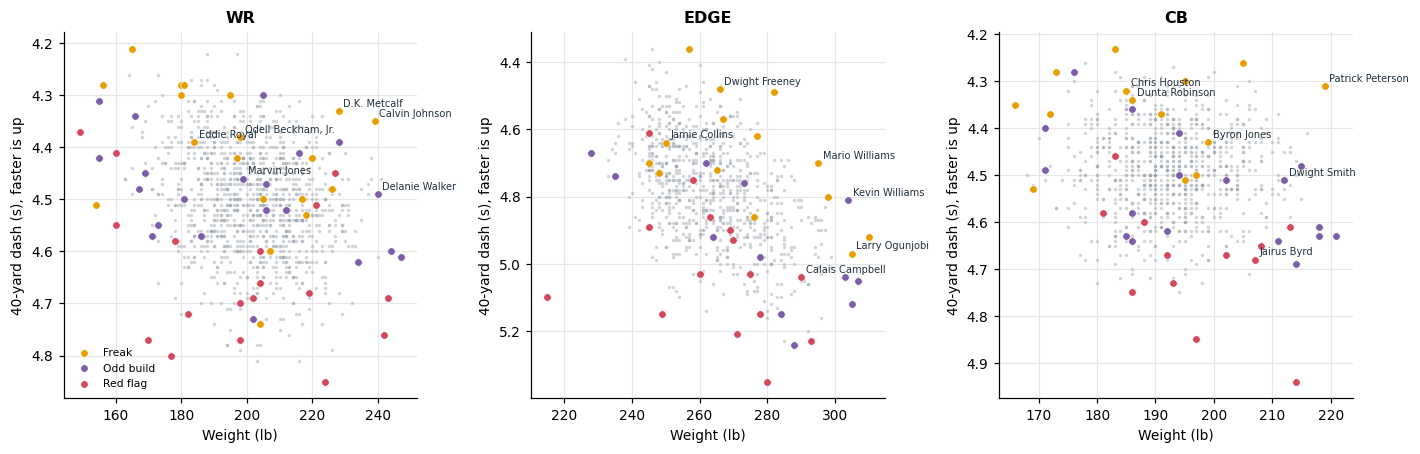

In [11]:
def scatter_types(ax, s, x, y):
    ax.scatter(s[~s.unicorn][x], s[~s.unicorn][y], s=5, color=TYPE_COLOR["Typical"], alpha=.45, lw=0)
    for t in TYPE_ORDER[:3]:
        u = s[s.utype == t]
        ax.scatter(u[x], u[y], s=24, color=TYPE_COLOR[t], edgecolor="white", lw=.4, label=t, zorder=3)


def label_points(ax, rows, x, y, fontsize=6.5):
    for _, r in rows.iterrows():
        ax.annotate(r.player_name, (r[x], r[y]), xytext=(3, 3), textcoords="offset points", fontsize=fontsize, color="#22303C")


fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, g in zip(axes, ["WR", "EDGE", "CB"]):
    s = df[df.grp == g]
    scatter_types(ax, s, "wt", "forty")
    label_points(ax, s[s.unicorn].nlargest(6, "w_av"), "wt", "forty")
    ax.invert_yaxis()
    ax.set(title=g, xlabel="Weight (lb)", ylabel="40-yard dash (s), faster is up")
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

**The full feature space, flattened.** Principal components compress each position's 7–8 features into two axes.
Unicorns form a ring around the central mass. PC1 is mostly a general athleticism axis, so Freaks and Red flags
tend to sit at opposite ends of it.

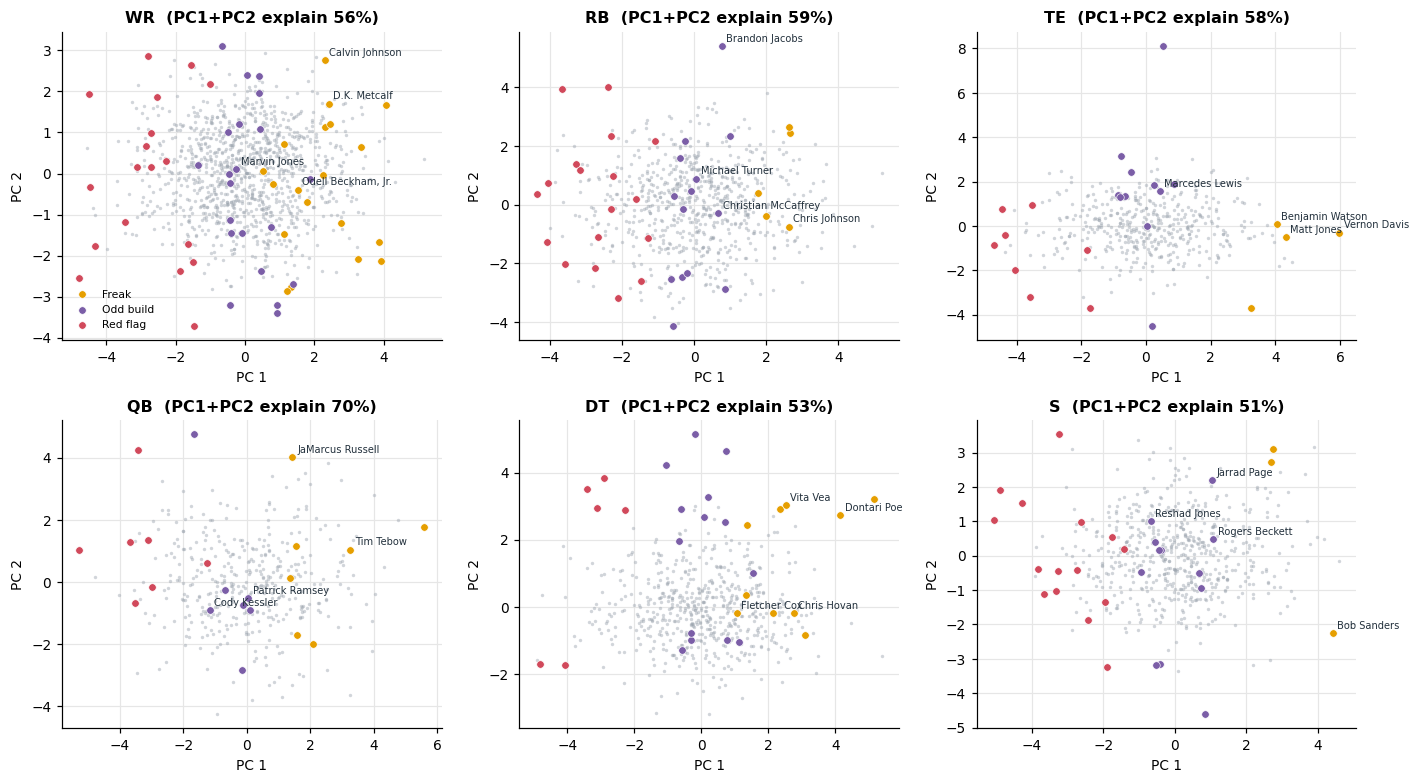

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, g in zip(axes.ravel(), ["WR", "RB", "TE", "QB", "DT", "S"]):
    s = df[df.grp == g].copy()
    cols = s.features.iloc[0].split(",")
    pca = PCA(n_components=2, random_state=SEED).fit(s[cols])
    s[["pc1", "pc2"]] = pca.transform(s[cols])
    scatter_types(ax, s, "pc1", "pc2")
    label_points(ax, s[s.unicorn].nlargest(4, "w_av"), "pc1", "pc2")
    ax.set(title=f"{g}  (PC1+PC2 explain {pca.explained_variance_ratio_.sum():.0%})", xlabel="PC 1", ylabel="PC 2")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**What makes them rare.** For every unicorn, the feature contributing most to his Mahalanobis distance; and how
many unicorns each class produced. 2021 spikes because, with no combine, its file includes many pro-day
participants who would never have been invited.

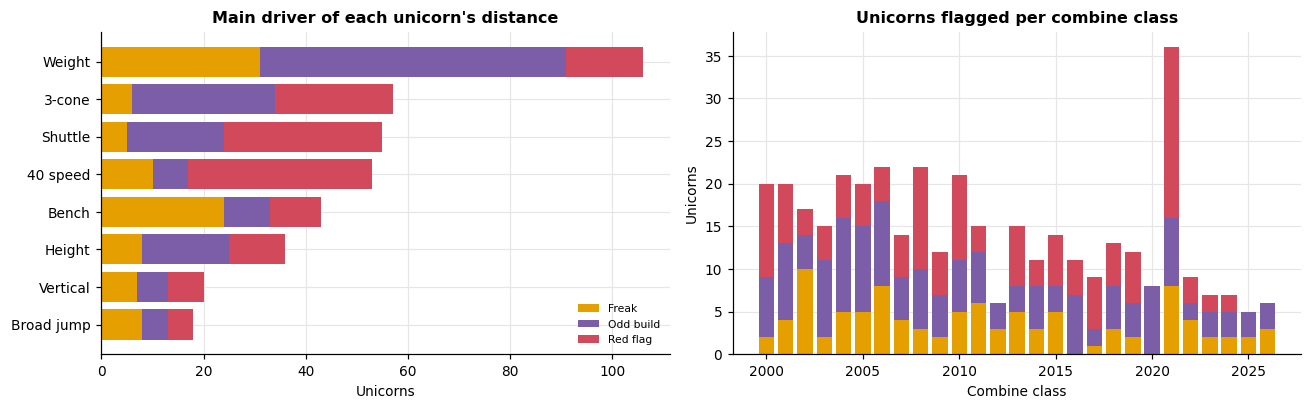

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
drivers = pd.crosstab(df[df.unicorn].driver, df[df.unicorn].utype).reindex(columns=TYPE_ORDER[:3]).fillna(0)
drivers = drivers.loc[drivers.sum(axis=1).sort_values().index]
left = np.zeros(len(drivers))
for t in TYPE_ORDER[:3]:
    axes[0].barh(drivers.index, drivers[t], left=left, color=TYPE_COLOR[t], label=t)
    left += drivers[t].values
axes[0].set(title="Main driver of each unicorn's distance", xlabel="Unicorns")
axes[0].legend(fontsize=7)
per_class = pd.crosstab(df[df.unicorn].season, df[df.unicorn].utype).reindex(columns=TYPE_ORDER[:3]).fillna(0)
bottom = np.zeros(len(per_class))
for t in TYPE_ORDER[:3]:
    axes[1].bar(per_class.index, per_class[t], bottom=bottom, color=TYPE_COLOR[t], label=t)
    bottom += per_class[t].values
axes[1].set(title="Unicorns flagged per combine class", xlabel="Combine class", ylabel="Unicorns")
plt.tight_layout()
plt.show()

## 5. Draft value: expected AV for every slot
Career **weighted Approximate Value** (AV) is Pro-Football-Reference's single-number summary of a career, comparable
across positions. A player's **expected** AV is the product of three factors:

$$E[\text{AV}] = f(\text{pick}) \times g(\text{class}) \times m(\text{position})$$

- **f(pick)**: a LOWESS smooth of career AV on log(pick) for the 2000–2015 classes (careers essentially complete),
  forced never to rise as the pick number grows.
- **g(class)**: the class's actual total AV divided by what *f* predicts. Near 1 for finished classes, lower for
  recent ones whose careers are still running, so a four-year veteran is compared fairly with a retired player.
- **m(position)**: AV is more generous to some positions (offensive linemen) than others (tight ends), so each
  position gets a multiplier.

The typical spread around expectation at each pick, σ(pick), is smoothed the same way. Then for each player:
**value over expected** VOE = AV − E[AV], the standardized **z** = VOE / σ, and the ratio r = AV / E[AV].

| Grade | Rule |
|---|---|
| **Steal** | z ≥ +0.75 and r ≥ 1.5 (well above the slot, at least 50% more than expected) |
| **Bust** | z ≤ −0.75 and r < 0.5 (well below the slot, less than half of what was expected) |
| **Good value** | everything in between |

A seventh-rounder who never plays is not a bust: almost nothing was expected of him.

,1,5,10,20,32,64,100,150,200,250
"Expected AV, f(pick)",67.600,52.700,47,41.100,34.600,23.400,16.200,10.200,7.100,6.100


vgrp,IOL,OT,LB,DT,EDGE,S,QB,RB,WR,CB,TE
Position multiplier m,1.360,1.160,1.110,1.040,1.020,1.020,1.010,0.960,0.870,0.810,0.680


grade,Bust,Good value,Steal
Round,,,
1,23.0%,58.8%,18.2%
2,24.1%,57.9%,18.0%
3,21.9%,59.9%,18.2%
4,20.2%,61.8%,18.0%
5,1.2%,80.6%,18.1%
6,0.0%,86.3%,13.7%
7,0.0%,87.4%,12.6%


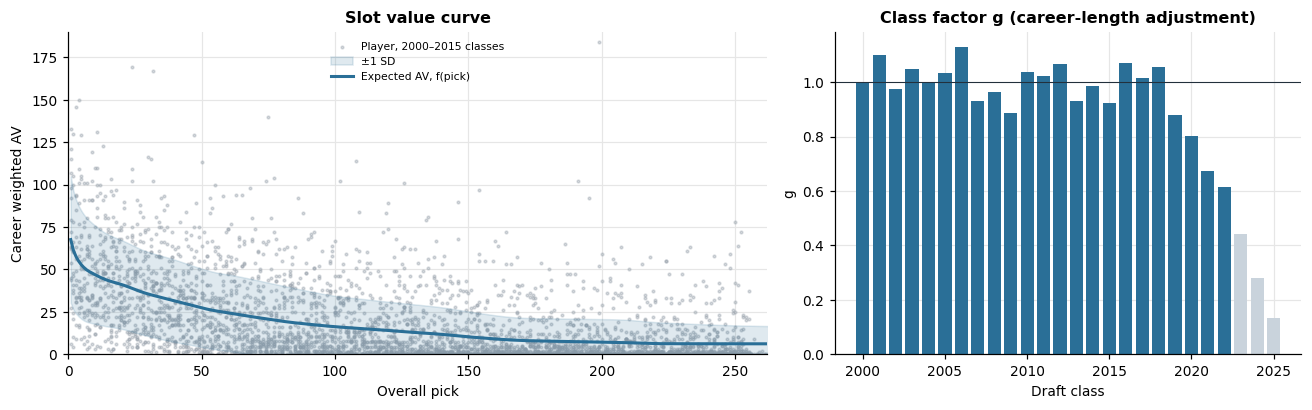

In [14]:
VALUE_POSITION = {"QB": "QB", "RB": "RB", "FB": "RB", "WR": "WR", "TE": "TE", "T": "OT", "OT": "OT",
                  "G": "IOL", "C": "IOL", "OL": "IOL", "OG": "IOL", "DT": "DT", "NT": "DT", "DL": "DT",
                  "DE": "EDGE", "OLB": "LB", "LB": "LB", "ILB": "LB", "CB": "CB", "DB": "CB",
                  "S": "S", "SAF": "S", "FS": "S", "SS": "S"}

picks = draft[draft.season.between(2000, 2025) & ~draft.position.isin(["K", "P", "LS"])].copy()
picks["av"] = picks.w_av.fillna(0).clip(lower=0)   # missing career AV counts as zero, as in the paper
picks = picks.merge(roster.rename(columns={"pfr_id": "pfr_player_id"}), on="pfr_player_id", how="left")
generic = picks.position.isin(["OL", "DL", "DB"]) & picks.nfl_pos.map(VALUE_POSITION).notna() \
          & ~picks.nfl_pos.isin(["OL", "DL", "DB", "LB", "OLB"])
picks["vgrp"] = np.where(generic, picks.nfl_pos.map(VALUE_POSITION), picks.position.map(VALUE_POSITION))
combine_group = df[df.drafted][["draft_year", "draft_ovr", "grp"]].rename(columns={"draft_year": "season", "draft_ovr": "pick"})
picks = picks.merge(combine_group, on=["season", "pick"], how="left")
picks["vgrp"] = picks.grp.fillna(picks.vgrp)
picks = picks[picks.vgrp.notna()].drop(columns="grp")

# f(pick)
mature = picks[picks.season <= MATURE_LAST]
grid = np.arange(1, 271)
f_curve = np.minimum.accumulate(lowess(mature.av, np.log(mature.pick), frac=.25, it=0, xvals=np.log(grid)))
picks["f"] = np.interp(picks.pick, grid, f_curve)
# g(class)
totals = picks.groupby("season")[["av", "f"]].sum()
class_factor = totals.av / totals.f
picks["g"] = picks.season.map(class_factor)
# m(position)
graded_era = picks[picks.season <= LAST_GRADED].assign(fg=lambda x: x.f * x.g)
pos_totals = graded_era.groupby("vgrp")[["av", "fg"]].sum()
position_mult = pos_totals.av / pos_totals.fg
picks["m"] = picks.vgrp.map(position_mult)
picks["exp_av"] = picks.f * picks.g * picks.m
# σ(pick)
mature = picks[picks.season <= MATURE_LAST]
scaled_resid = (mature.av - mature.exp_av) / (mature.g * mature.m)
sd_curve = np.sqrt(np.clip(lowess(scaled_resid ** 2, np.log(mature.pick), frac=.3, it=0, xvals=np.log(grid)), 1e-6, None))
picks["sd_av"] = np.interp(picks.pick, grid, sd_curve) * picks.g * picks.m
picks["voe"] = picks.av - picks.exp_av
picks["z"] = picks.voe / picks.sd_av
picks["ratio"] = picks.av / picks.exp_av


def grade(row):
    if row.season > LAST_GRADED:
        return "Too early"
    if row.z >= .75 and row.ratio >= 1.5:
        return "Steal"
    if row.z <= -.75 and row.ratio < .5:
        return "Bust"
    return "Good value"


picks["grade"] = picks.apply(grade, axis=1)

display(pd.Series(f_curve, index=grid)[[1, 5, 10, 20, 32, 64, 100, 150, 200, 250]].round(1).rename("Expected AV, f(pick)").to_frame().T)
display(position_mult.sort_values(ascending=False).round(2).rename("Position multiplier m").to_frame().T)
in_graded = picks[picks.season <= LAST_GRADED]
display(pd.crosstab(in_graded["round"], in_graded.grade, normalize="index").mul(100).round(1)
        .rename_axis("Round").style.format("{:.1f}%").set_caption("Grade mix by round, all players drafted 2000–2022"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].scatter(mature.pick, mature.av, s=3, color=TYPE_COLOR["Typical"], alpha=.4, label="Player, 2000–2015 classes")
axes[0].fill_between(grid, np.clip(f_curve - sd_curve, 0, None), f_curve + sd_curve, color="#2A6F97", alpha=.15, label="±1 SD")
axes[0].plot(grid, f_curve, color="#2A6F97", lw=2, label="Expected AV, f(pick)")
axes[0].set(title="Slot value curve", xlabel="Overall pick", ylabel="Career weighted AV", ylim=(0, 190), xlim=(0, 262))
axes[0].legend(fontsize=7)
axes[1].bar(class_factor.index, class_factor.values, color=np.where(class_factor.index <= LAST_GRADED, "#2A6F97", "#c9d3dc"))
axes[1].axhline(1, color="#22303C", lw=.7)
axes[1].set(title="Class factor g (career-length adjustment)", xlabel="Draft class", ylabel="g")
plt.tight_layout()
plt.show()

### Join detection and value
Every drafted prospect gets his slot's expected AV, z and grade. Drafted players from 2023 onward are **Too early**;
prospects without a pick are **Undrafted**. The analysis sample (**graded**) is everyone drafted 2000–2022.

In [15]:
value_cols = picks[["season", "pick", "av", "exp_av", "sd_av", "voe", "z", "ratio", "grade"]] \
    .rename(columns={"season": "draft_year", "pick": "draft_ovr"})
df = df.merge(value_cols, on=["draft_year", "draft_ovr"], how="left", validate="many_to_one")
df["grade"] = np.where(df.drafted, df.grade.fillna("Too early"), "Undrafted")
graded = df[df.grade.isin(["Bust", "Good value", "Steal"])].copy()
graded["log_pick"] = np.log(graded.draft_ovr)
graded["round_band"] = pd.cut(graded.draft_round, [0, 1, 3, 7], labels=["Round 1", "Rounds 2–3", "Rounds 4–7"])
display(df.grade.value_counts().rename("Prospects").to_frame())
print(f"Graded sample: {len(graded):,} drafted players, including {graded.unicorn.sum()} unicorns")

,Prospects
grade,
Good value,3102
Undrafted,2609
Steal,786
Bust,638
Too early,555


Graded sample: 4,526 drafted players, including 202 unicorns


## 6. What the market pays for a unicorn
Before asking what unicorns return, measure what they cost: how often each type is drafted and how early.
Two regressions then separate **athleticism** (direction) from **rarity** (the Mahalanobis percentile):
- a **logit** of being drafted, and
- an **OLS** of log(pick) among those drafted,

both with position fixed effects.

,prospects,drafted_pct,median_pick,round1_pct
utype,,,,
Freak,96,88.500,68,31.800
Odd build,148,62.200,99.500,16.300
Red flag,138,26.800,162,0.000
Typical,7119,66.400,108.500,14.700


,P(drafted): log-odds,p (logit),log(pick) if drafted,p (OLS)
Athleticism (per SD),0.784,0.000,-0.307,0.000
Mahalanobis percentile (0–1),-0.440,0.000,0.005,0.906


One SD of athleticism multiplies the odds of being drafted by 2.19.


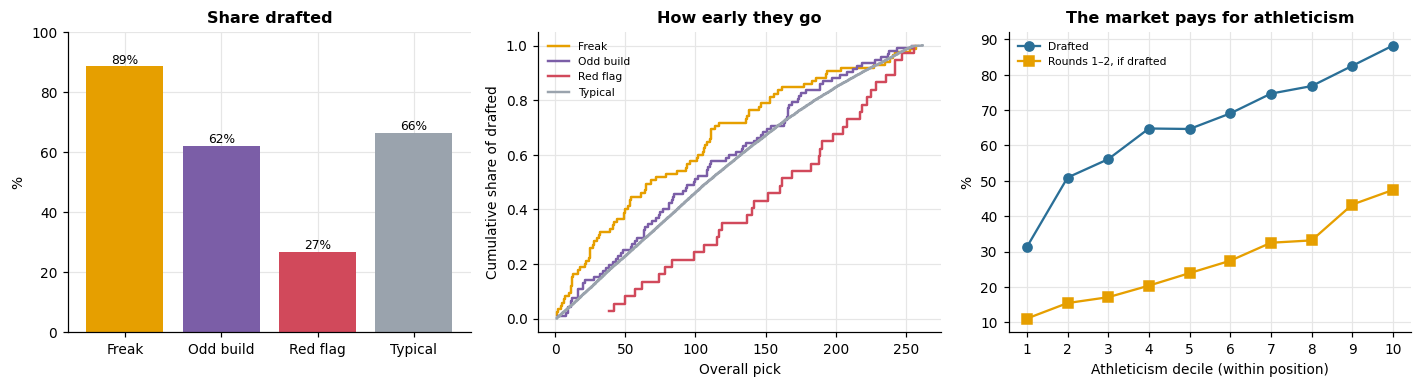

In [16]:
pool = df[df.season <= 2025].copy()
selection = pool.groupby("utype").agg(prospects=("player_name", "size"), drafted_pct=("drafted", "mean"))
drafted_pool = pool[pool.drafted]
selection["median_pick"] = drafted_pool.groupby("utype").draft_ovr.median()
selection["round1_pct"] = drafted_pool.groupby("utype").draft_round.apply(lambda r: (r == 1).mean())
selection = selection.reindex(TYPE_ORDER)
selection[["drafted_pct", "round1_pct"]] *= 100
display(selection.round(1))

pool["drafted_int"] = pool.drafted.astype(int)
logit = smf.logit("drafted_int ~ ath_z + md_pct + C(grp)", pool).fit(disp=0)
drafted_pool = drafted_pool.assign(log_pick=np.log(drafted_pool.draft_ovr))
pick_ols = smf.ols("log_pick ~ ath_z + md_pct + C(grp)", drafted_pool).fit(cov_type="HC1")
premium = pd.DataFrame({
    "P(drafted): log-odds": logit.params[["ath_z", "md_pct"]], "p (logit)": logit.pvalues[["ath_z", "md_pct"]],
    "log(pick) if drafted": pick_ols.params[["ath_z", "md_pct"]], "p (OLS)": pick_ols.pvalues[["ath_z", "md_pct"]]},
    ).rename(index={"ath_z": "Athleticism (per SD)", "md_pct": "Mahalanobis percentile (0–1)"})
display(premium.round(3))
print(f"One SD of athleticism multiplies the odds of being drafted by {np.exp(logit.params['ath_z']):.2f}.")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
bars = axes[0].bar(TYPE_ORDER, selection.drafted_pct, color=[TYPE_COLOR[t] for t in TYPE_ORDER])
axes[0].bar_label(bars, fmt="%.0f%%", fontsize=8)
axes[0].set(title="Share drafted", ylabel="%", ylim=(0, 100))
for t in TYPE_ORDER:
    x = np.sort(drafted_pool[drafted_pool.utype == t].draft_ovr)
    axes[1].step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=TYPE_COLOR[t], lw=1.6, label=t)
axes[1].set(title="How early they go", xlabel="Overall pick", ylabel="Cumulative share of drafted")
axes[1].legend(fontsize=7)
pool["ath_decile"] = pd.qcut(pool.ath_z, 10, labels=False) + 1
by_decile = pool.groupby("ath_decile").drafted.mean() * 100
early = pool[pool.drafted].groupby("ath_decile").draft_round.apply(lambda r: (r <= 2).mean() * 100)
axes[2].plot(by_decile.index, by_decile, marker="o", color="#2A6F97", label="Drafted")
axes[2].plot(early.index, early, marker="s", color=TYPE_COLOR["Freak"], label="Rounds 1–2, if drafted")
axes[2].set(title="The market pays for athleticism", xlabel="Athleticism decile (within position)", ylabel="%", xticks=range(1, 11))
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 7. What teams got: bust, good value or steal
The core comparison. Because z already nets out pick, class and position, the mean z of each type is a fair
comparison. Intervals are **percentile bootstraps** (resample players 4,000 times). We add Welch t-tests and
Mann–Whitney tests on z, and χ² tests on the grade mix, each against Typical players.

,n,Median pick,Mean AV,Mean expected AV,Mean VOE,Mean z,CI low,CI high,Bust %,Good %,Steal %
Type,,,,,,,,,,,
Freak,79,72,24.970,24.270,0.710,0.050,-0.130,0.250,13.920,65.820,20.250
Odd build,87,94,18.820,20,-1.180,-0.040,-0.230,0.180,17.240,66.670,16.090
Red flag,36,161,10.970,12.130,-1.160,-0.170,-0.410,0.140,11.110,80.560,8.330
Typical,4324,108,18.920,18.700,0.220,0.020,-0.010,0.050,14.060,68.520,17.410
All unicorns,202,101.500,19.830,20.270,-0.440,-0.030,-0.150,0.100,14.850,68.810,16.340


,Welch t p,Mann–Whitney p,χ² grade-mix p
Type vs Typical,,,
Freak,0.734,0.368,0.802
Odd build,0.566,0.517,0.691
Red flag,0.209,0.153,0.263


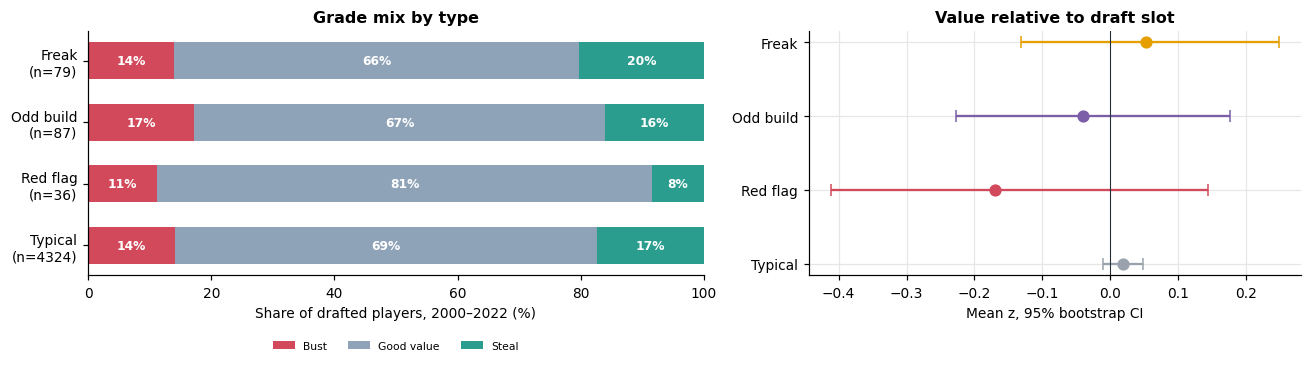

In [17]:
def bootstrap_ci(values, n=N_BOOT):
    values = np.asarray(values)
    means = RNG.choice(values, size=(n, len(values))).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def value_row(group, label):
    low, high = bootstrap_ci(group.z)
    mix = group.grade.value_counts(normalize=True)
    return {"Type": label, "n": len(group), "Median pick": group.draft_ovr.median(), "Mean AV": group.av.mean(),
            "Mean expected AV": group.exp_av.mean(), "Mean VOE": group.voe.mean(), "Mean z": group.z.mean(),
            "CI low": low, "CI high": high, "Bust %": 100 * mix.get("Bust", 0),
            "Good %": 100 * mix.get("Good value", 0), "Steal %": 100 * mix.get("Steal", 0)}


value_table = pd.DataFrame([value_row(graded[graded.utype == t], t) for t in TYPE_ORDER]
                           + [value_row(graded[graded.unicorn], "All unicorns")]).set_index("Type")
display(value_table.round(2))

typical = graded[graded.utype == "Typical"]
tests = []
for t in TYPE_ORDER[:3]:
    group = graded[graded.utype == t]
    both = graded[graded.utype.isin([t, "Typical"])]
    tests.append({"Type vs Typical": t,
                  "Welch t p": stats.ttest_ind(group.z, typical.z, equal_var=False).pvalue,
                  "Mann–Whitney p": stats.mannwhitneyu(group.z, typical.z).pvalue,
                  "χ² grade-mix p": stats.chi2_contingency(pd.crosstab(both.utype, both.grade))[1]})
display(pd.DataFrame(tests).set_index("Type vs Typical").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.25, 1]})
mix = pd.crosstab(graded.utype, graded.grade, normalize="index").reindex(TYPE_ORDER)[["Bust", "Good value", "Steal"]] * 100
left = np.zeros(4)
for gname in ["Bust", "Good value", "Steal"]:
    axes[0].barh(TYPE_ORDER, mix[gname], left=left, color=GRADE_COLOR[gname], label=gname, height=.6)
    for i, (w, l) in enumerate(zip(mix[gname], left)):
        axes[0].text(l + w / 2, i, f"{w:.0f}%", ha="center", va="center", fontsize=8, color="white", fontweight="bold")
    left += mix[gname].values
axes[0].set_yticks(range(4), [f"{t}\n(n={(graded.utype == t).sum()})" for t in TYPE_ORDER])
axes[0].invert_yaxis()
axes[0].set(xlim=(0, 100), xlabel="Share of drafted players, 2000–2022 (%)", title="Grade mix by type")
axes[0].legend(ncol=3, fontsize=7, loc="lower center", bbox_to_anchor=(.5, -.35))
axes[0].grid(False)
for i, t in enumerate(TYPE_ORDER):
    r = value_table.loc[t]
    axes[1].errorbar(r["Mean z"], i, xerr=[[r["Mean z"] - r["CI low"]], [r["CI high"] - r["Mean z"]]],
                     fmt="o", color=TYPE_COLOR[t], capsize=4, ms=7)
axes[1].axvline(0, color="#22303C", lw=.7)
axes[1].set_yticks(range(4), TYPE_ORDER)
axes[1].invert_yaxis()
axes[1].set(title="Value relative to draft slot", xlabel="Mean z, 95% bootstrap CI")
plt.tight_layout()
plt.show()

### Regression with controls
Two OLS models of z on all 2000–2022 picks, each with log(pick), position and draft-class fixed effects and
heteroskedasticity-robust (HC1) standard errors:
- **Model 1**: unicorn type dummies (Typical = baseline).
- **Model 2**: the two continuous scores, athleticism and Mahalanobis percentile, plus their interaction (Model 3).

Model 2 is the cleanest test of the paper's question: *is it being better, or being different, that pays?*

In [18]:
controls = "log_pick + C(grp) + C(draft_year)"
m1 = smf.ols(f"z ~ C(utype, Treatment('Typical')) + {controls}", graded).fit(cov_type="HC1")
m2 = smf.ols(f"z ~ ath_z + md_pct + {controls}", graded).fit(cov_type="HC1")
m3 = smf.ols(f"z ~ ath_z * md_pct + {controls}", graded).fit(cov_type="HC1")


def coef_table(model, terms, names):
    ci = model.conf_int()
    return pd.DataFrame({"Coef": model.params[terms].values, "Robust SE": model.bse[terms].values,
                         "CI low": ci.loc[terms, 0].values, "CI high": ci.loc[terms, 1].values,
                         "p": model.pvalues[terms].values}, index=names)


type_terms = [f"C(utype, Treatment('Typical'))[T.{t}]" for t in TYPE_ORDER[:3]]
regressions = pd.concat({
    "Model 1: type vs Typical": coef_table(m1, type_terms, TYPE_ORDER[:3]),
    "Model 2: continuous": coef_table(m2, ["ath_z", "md_pct"], ["Athleticism (per SD)", "Mahalanobis pct (0–1)"]),
    "Model 3: interaction": coef_table(m3, ["ath_z:md_pct"], ["Athleticism × Mahalanobis pct"]),
})
display(regressions.round(3))
print(f"Observations: {int(m1.nobs):,}")

Coef  Robust SE  CI low  CI high     p
Model 1: type vs Typical Freak                          0.032      0.099  -0.163    0.226 0.750
                         Odd build                     -0.055      0.104  -0.258    0.149 0.597
                         Red flag                      -0.193      0.149  -0.486    0.099 0.196
Model 2: continuous      Athleticism (per SD)           0.037      0.018   0.002    0.072 0.039
                         Mahalanobis pct (0–1)          0.062      0.053  -0.041    0.166 0.238
Model 3: interaction     Athleticism × Mahalanobis pct  0.007      0.064  -0.118    0.133 0.907

Observations: 4,526


**Across the whole population.** Mean value over slot by decile of athleticism (left) and of Mahalanobis rarity
(right). If rarity itself carried value, the right panel would climb.

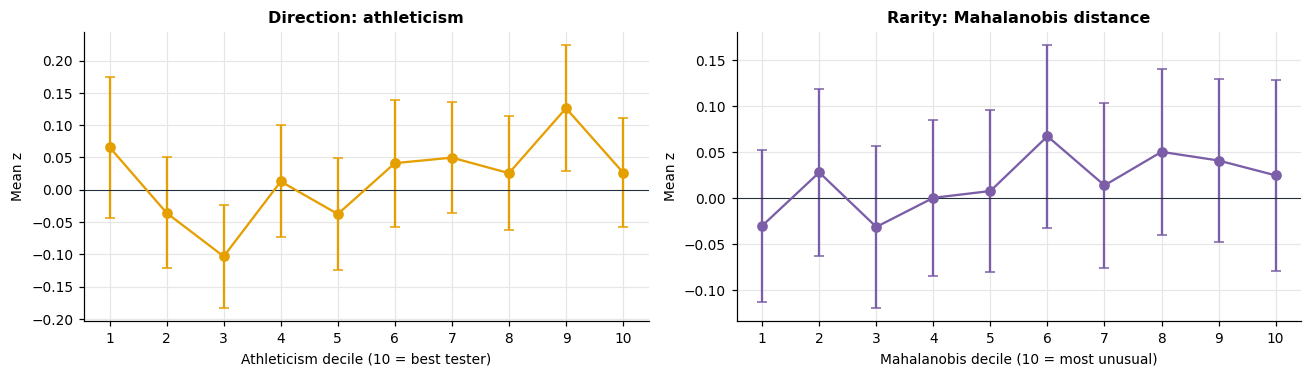

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col, label, color in [(axes[0], "ath_z", "Athleticism decile (10 = best tester)", TYPE_COLOR["Freak"]),
                              (axes[1], "md_pct", "Mahalanobis decile (10 = most unusual)", TYPE_COLOR["Odd build"])]:
    decile = pd.qcut(graded[col], 10, labels=False) + 1
    stats_by = graded.groupby(decile).z.agg(["mean", "sem"])
    ax.errorbar(stats_by.index, stats_by["mean"], yerr=1.96 * stats_by["sem"], fmt="o-", color=color, capsize=3)
    ax.axhline(0, color="#22303C", lw=.7)
    ax.set(xlabel=label, ylabel="Mean z", xticks=range(1, 11))
axes[0].set_title("Direction: athleticism")
axes[1].set_title("Rarity: Mahalanobis distance")
plt.tight_layout()
plt.show()

### By round
The average can hide structure. A Freak taken in round one is a different bet from a Freak still available on day three.

,round_band,utype,n,mean_voe,mean_z,bust_pct,steal_pct
0,Round 1,Freak,24,6.210,0.270,12.500,29.170
1,Round 1,Odd build,15,-3.060,-0.150,26.670,13.330
2,Round 1,Typical,649,-1.120,-0.040,22.960,18.340
3,Rounds 2–3,Freak,21,-3.130,-0.090,23.810,19.050
4,Rounds 2–3,Odd build,30,-4.520,-0.250,30,13.330
5,Rounds 2–3,Red flag,9,12.700,0.560,22.220,33.330
6,Rounds 2–3,Typical,1347,0.200,0.010,23.460,18.110
7,Rounds 4–7,Freak,34,-0.800,-0.010,8.820,14.710
8,Rounds 4–7,Odd build,42,1.870,0.150,4.760,19.050
9,Rounds 4–7,Red flag,27,-5.780,-0.420,7.410,0.000


Round-1 Freaks (n=24): mean z +0.27 [95% CI -0.09, +0.63], Welch p vs other first-rounders = 0.119; bust 12% vs 23% (Fisher p=0.321); steal 29% vs 18% (Fisher p=0.185)
Cells with fewer than 8 players are left blank.


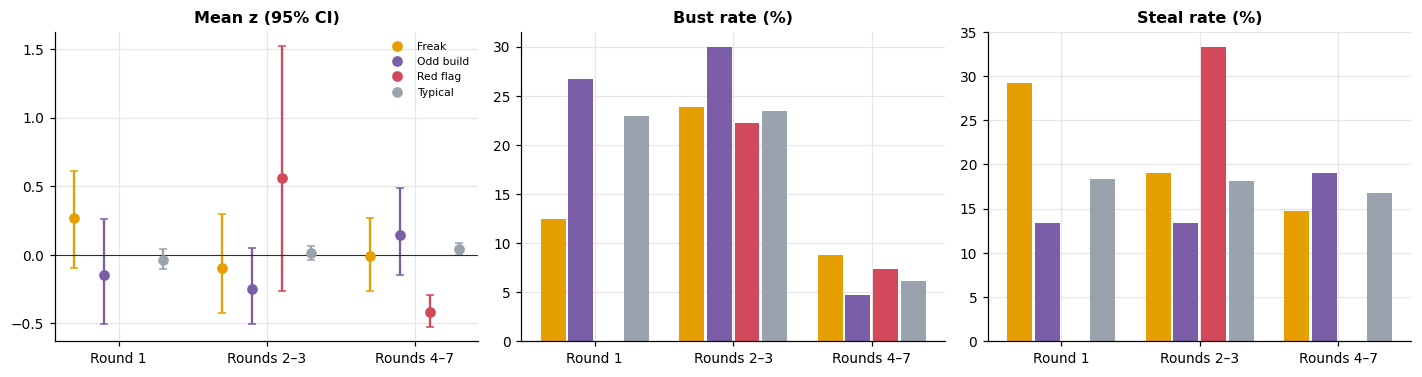

In [20]:
by_round = graded.groupby(["round_band", "utype"], observed=True).agg(
    n=("z", "size"), mean_voe=("voe", "mean"), mean_z=("z", "mean"),
    bust_pct=("grade", lambda g: 100 * (g == "Bust").mean()),
    steal_pct=("grade", lambda g: 100 * (g == "Steal").mean())).reset_index()
display(by_round.round(2))

r1_freak = graded[(graded.draft_round == 1) & (graded.utype == "Freak")]
r1_typical = graded[(graded.draft_round == 1) & (graded.utype == "Typical")]
if len(r1_freak) > 2:
    fisher = lambda col: stats.fisher_exact([[(r1_freak.grade == col).sum(), (r1_freak.grade != col).sum()],
                                             [(r1_typical.grade == col).sum(), (r1_typical.grade != col).sum()]])[1]
    low, high = bootstrap_ci(r1_freak.z)
    print(f"Round-1 Freaks (n={len(r1_freak)}): mean z {r1_freak.z.mean():+.2f} [95% CI {low:+.2f}, {high:+.2f}], "
          f"Welch p vs other first-rounders = {stats.ttest_ind(r1_freak.z, r1_typical.z, equal_var=False).pvalue:.3f}; "
          f"bust {100 * (r1_freak.grade == 'Bust').mean():.0f}% vs {100 * (r1_typical.grade == 'Bust').mean():.0f}% "
          f"(Fisher p={fisher('Bust'):.3f}); steal {100 * (r1_freak.grade == 'Steal').mean():.0f}% vs "
          f"{100 * (r1_typical.grade == 'Steal').mean():.0f}% (Fisher p={fisher('Steal'):.3f})")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
bands = ["Round 1", "Rounds 2–3", "Rounds 4–7"]
width = .2
for i, t in enumerate(TYPE_ORDER):
    for j, band in enumerate(bands):
        z = graded[(graded.utype == t) & (graded.round_band == band)].z
        if len(z) < 8:
            continue
        low, high = bootstrap_ci(z, 2000)
        axes[0].errorbar(j + (i - 1.5) * width, z.mean(), yerr=[[z.mean() - low], [high - z.mean()]], fmt="o",
                         color=TYPE_COLOR[t], capsize=2.5, label=t if j == 0 else None)
    for ax, col in [(axes[1], "bust_pct"), (axes[2], "steal_pct")]:
        cell = by_round[(by_round.utype == t) & (by_round.n >= 8)].set_index("round_band")[col]
        vals = [cell.get(b, np.nan) for b in bands]
        ax.bar(np.arange(3) + (i - 1.5) * width, vals, width * .9, color=TYPE_COLOR[t])
axes[0].axhline(0, color="#22303C", lw=.7)
for ax, title in zip(axes, ["Mean z (95% CI)", "Bust rate (%)", "Steal rate (%)"]):
    ax.set_xticks(range(3), bands)
    ax.set_title(title)
axes[0].legend(handles=[Line2D([], [], marker="o", ls="", color=TYPE_COLOR[t], label=t) for t in TYPE_ORDER], fontsize=7)
print("Cells with fewer than 8 players are left blank.")
plt.tight_layout()
plt.show()

### By position
Samples are small at this level; read the shape, not the decimals. The tick marks show typical players at the same position.

,n,unicorn_mean_z,steal_pct,bust_pct,typical_mean_z
grp,,,,,
QB,10,-0.790,0.000,50,0.030
IOL,18,-0.150,11.110,22.220,0.060
LB,20,-0.130,5,15,0.010
S,12,-0.110,16.670,8.330,-0.020
TE,13,-0.060,7.690,0.000,-0.010
OT,12,-0.040,25,33.330,-0.000
DT,20,0.030,20,10,0.030
EDGE,26,0.060,19.230,11.540,0.020
WR,29,0.100,20.690,13.790,0.010


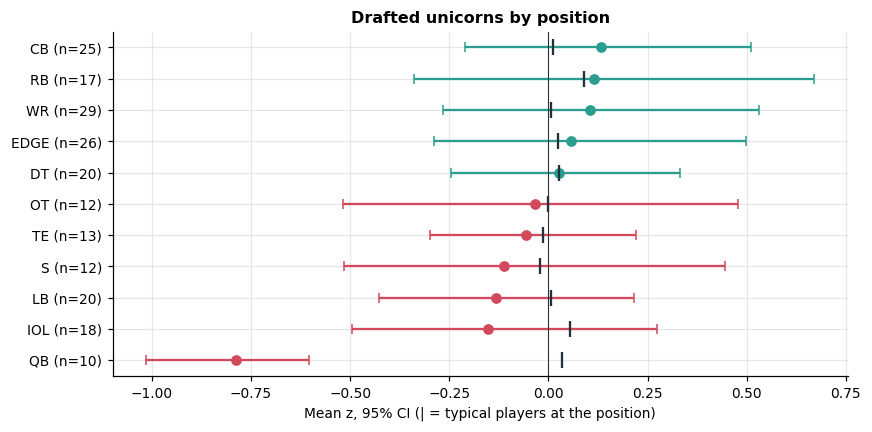

In [21]:
uni = graded[graded.unicorn]
by_pos = uni.groupby("grp").agg(n=("z", "size"), unicorn_mean_z=("z", "mean"),
                                steal_pct=("grade", lambda g: 100 * (g == "Steal").mean()),
                                bust_pct=("grade", lambda g: 100 * (g == "Bust").mean()))
by_pos["typical_mean_z"] = typical.groupby("grp").z.mean()
by_pos = by_pos.sort_values("unicorn_mean_z")
display(by_pos.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
for i, (g, r) in enumerate(by_pos.iterrows()):
    z = uni[uni.grp == g].z
    low, high = bootstrap_ci(z, 2000) if len(z) > 1 else (z.mean(), z.mean())
    color = GRADE_COLOR["Steal"] if r.unicorn_mean_z > 0 else GRADE_COLOR["Bust"]
    ax.errorbar(r.unicorn_mean_z, i, xerr=[[r.unicorn_mean_z - low], [high - r.unicorn_mean_z]], fmt="o", color=color, capsize=3)
    ax.scatter(r.typical_mean_z, i, marker="|", s=120, color="#22303C", zorder=4)
ax.set_yticks(range(len(by_pos)), [f"{g} (n={int(n)})" for g, n in by_pos.n.items()])
ax.axvline(0, color="#22303C", lw=.7)
ax.set(title="Drafted unicorns by position", xlabel="Mean z, 95% CI (| = typical players at the position)")
plt.tight_layout()
plt.show()

### The players
Every graded unicorn by pick and career AV, coloured by grade. The dashed line is the position-neutral slot curve.

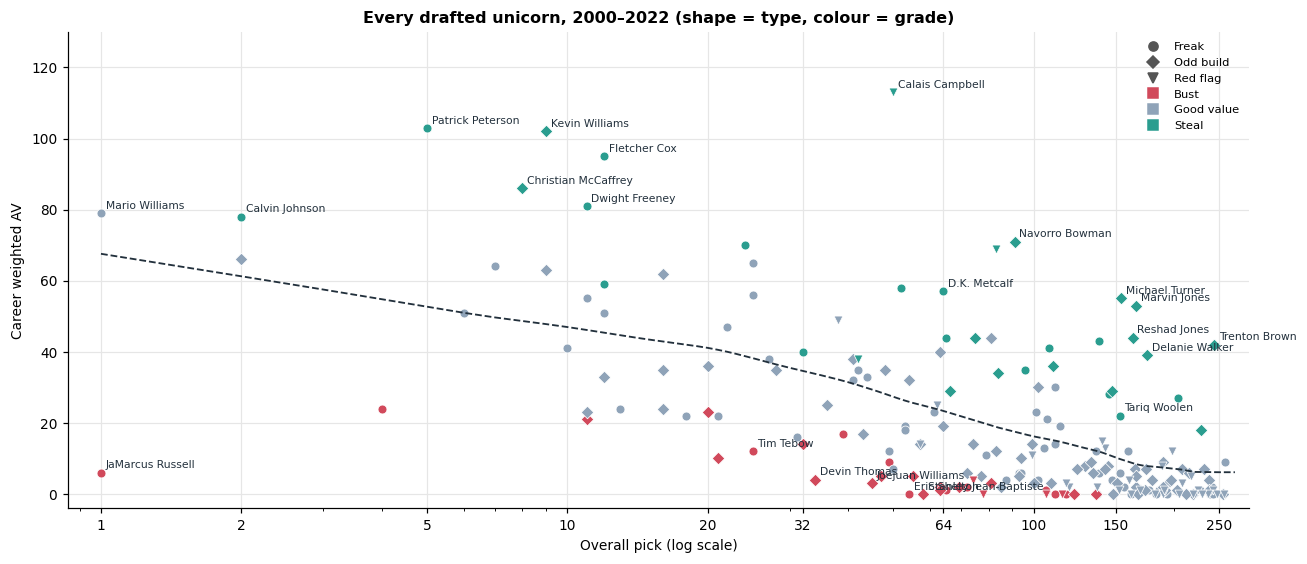

**Biggest unicorn steals**

,player_name,grp,utype,driver,draft_year,draft_ovr,franchise,av,exp_av,z,grade
2480,Calais Campbell,EDGE,Red flag,Height,2008,50,ARI,113,26.970,3.770,Steal
3817,Marvin Jones,WR,Odd build,Bench,2012,166,CIN,53,7.780,3.590,Steal
1468,Michael Turner,RB,Odd build,3-cone,2004,154,LAC,55,9.290,3.290,Steal
4633,Trenton Brown,IOL,Odd build,Weight,2015,244,SFO,42,7.690,2.450,Steal
3184,Reshad Jones,S,Odd build,Shuttle,2010,163,MIA,44,9.100,2.420,Steal
2092,Delanie Walker,WR,Odd build,Weight,2006,175,SFO,39,7.710,2.380,Steal
6854,Tariq Woolen,CB,Freak,Height,2022,153,SEA,22,4.910,2.340,Steal
3072,Navorro Bowman,LB,Odd build,Shuttle,2010,91,SFO,71,20.140,2.280,Steal
5902,D.K. Metcalf,WR,Freak,Bench,2019,64,SEA,57,17.870,2.280,Steal
3562,Patrick Peterson,CB,Freak,Weight,2011,5,ARI,103,43.800,2.240,Steal


**Biggest unicorn busts**

,player_name,grp,utype,driver,draft_year,draft_ovr,franchise,av,exp_av,z,grade
2350,JaMarcus Russell,QB,Freak,Weight,2007,1,LVR,6,63.740,-1.640,Bust
2712,Devin Thomas,WR,Odd build,Vertical,2008,34,WAS,4,28.400,-1.180,Bust
1770,Eric Shelton,RB,Freak,Shuttle,2005,54,CAR,0.000,25.670,-1.140,Bust
4425,Stanley Jean-Baptiste,CB,Odd build,Weight,2014,58,NOR,0.000,19.920,-1.100,Bust
5988,Joejuan Williams,CB,Odd build,Height,2019,45,NWE,3,21,-1.060,Bust
3303,Tim Tebow,QB,Freak,Vertical,2010,25,DEN,12,40.060,-1.060,Bust
887,Mike Williams,OT,Freak,Weight,2002,4,BUF,24,62.080,-1.030,Bust
6195,Jalen Reagor,WR,Odd build,Broad jump,2020,21,PHI,10,28.390,-1.010,Bust
1310,Marquise Hill,EDGE,Odd build,Weight,2004,63,NWE,1,24.120,-1.010,Bust
2073,Charles Spencer,IOL,Freak,Weight,2006,65,HOU,1,35.410,-1,Bust


**Most anomalous drafted Freaks**

,player_name,grp,draft_year,ht,wt,forty,ath_z,driver,draft_ovr,franchise,av,exp_av,z,grade
573,T.J. Turner,LB,2001,75,273,4.800,1.060,Weight,239,NWE,0.000,7.500,-0.540,Good value
887,Mike Williams,OT,2002,78,375,5.300,0.850,Weight,4,BUF,24,62.080,-1.030,Bust
4502,Jeoffrey Pagan,EDGE,2014,75,310,4.920,1.340,Weight,177,HOU,1,7.830,-0.510,Good value
3784,Dont'a Hightower,LB,2012,74,265,4.620,0.940,Weight,25,NWE,65,45.250,0.660,Good value
6673,Jordan Davis,DT,2022,78,341,4.780,3.080,Broad jump,13,PHI,24,28.570,-0.260,Good value
5902,D.K. Metcalf,WR,2019,75,228,4.330,1.400,Bench,64,SEA,57,17.870,2.280,Steal
127,Chris Hovan,DT,2000,74,305,4.990,2.080,3-cone,25,MIN,56,39.880,0.610,Good value
505,Mathias Nkwenti,IOL,2001,75,293,5.570,1.240,40 speed,111,PIT,0.000,22.430,-0.860,Bust
649,Rock Cartwright,RB,2002,68,237,4.470,1.400,Weight,257,WAS,9,5.700,0.330,Good value
6854,Tariq Woolen,CB,2022,76,205,4.260,2.280,Height,153,SEA,22,4.910,2.340,Steal


In [22]:
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.plot(grid, f_curve, color="#22303C", ls="--", lw=1.2, label="Slot expectation")
markers = {"Freak": "o", "Odd build": "D", "Red flag": "v"}
for t, mk in markers.items():
    for gname, color in GRADE_COLOR.items():
        s = uni[(uni.utype == t) & (uni.grade == gname)]
        ax.scatter(s.draft_ovr, s.av, marker=mk, s=34, color=color, edgecolor="white", lw=.5)
named = pd.concat([uni.nlargest(10, "z"), uni.nsmallest(6, "z"), uni.nlargest(8, "av")]).drop_duplicates("player_name")
label_points(ax, named[named.av < 125], "draft_ovr", "av", fontsize=7)
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 20, 32, 64, 100, 150, 250], [1, 2, 5, 10, 20, 32, 64, 100, 150, 250])
ax.set(xlim=(.85, 290), ylim=(-4, 130), xlabel="Overall pick (log scale)", ylabel="Career weighted AV",
       title="Every drafted unicorn, 2000–2022 (shape = type, colour = grade)")
handles = [Line2D([], [], marker=m, ls="", color="#555", label=t) for t, m in markers.items()] + \
          [Line2D([], [], marker="s", ls="", color=c, label=g) for g, c in GRADE_COLOR.items()]
ax.legend(handles=handles, fontsize=7.5, loc="upper right")
plt.tight_layout()
plt.show()

show = ["player_name", "grp", "utype", "driver", "draft_year", "draft_ovr", "franchise", "av", "exp_av", "z", "grade"]
display(Markdown("**Biggest unicorn steals**"))
display(uni.nlargest(12, "z")[show].round(2))
display(Markdown("**Biggest unicorn busts**"))
display(uni.nsmallest(12, "z")[show].round(2))
display(Markdown("**Most anomalous drafted Freaks**"))
display(graded[graded.utype == "Freak"].nlargest(15, "md_score")[["player_name", "grp", "draft_year", "ht", "wt", "forty", "ath_z",
                                                                  "driver", "draft_ovr", "franchise", "av", "exp_av", "z", "grade"]].round(2))

## 8. Unicorn archetypes (k-means)
To describe *how* unicorns are unusual, we cluster all unicorns on six summary dimensions: height, weight,
adjusted speed, explosion (jumps), agility (cone and shuttle) and strength (bench). Silhouette scores are low for
every k (about 0.2), so these are regions of a continuum rather than crisp species. We use k = 5, as in the paper,
because five centres are easy to read. Each archetype is named automatically from its two most extreme traits.

,3,4,5,6,7,8
Silhouette,0.223,0.200,0.211,0.190,0.190,0.186


,n,ath_z,positions,graded,mean_z,steal_pct,bust_pct,examples
archetype,,,,,,,,
Strong & Explosive,51,1,"WR, EDGE, DT",34,0.280,20.590,11.760,"Dwight Freeney, Mario Williams, Navorro Bowman..."
Heavy & Tall,97,-0.040,"OT, IOL, DT",66,0.010,22.730,22.730,"Calais Campbell, Patrick Peterson, Kevin Willi..."
Tall & Fast,66,0.690,"CB, LB, WR",42,-0.020,19.050,14.290,"Fletcher Cox, Christian McCaffrey, Calvin John..."
Slow & Stiff,104,-2.230,"EDGE, RB, LB",25,-0.240,8,8,"Orlando Brown, Rey Maualuga, Jairus Byrd, Bran..."
Light & Short,70,0.260,"WR, RB, EDGE",35,-0.250,2.860,8.570,"Derrick Burgess, Bob Sanders, Bobby McCain, To..."


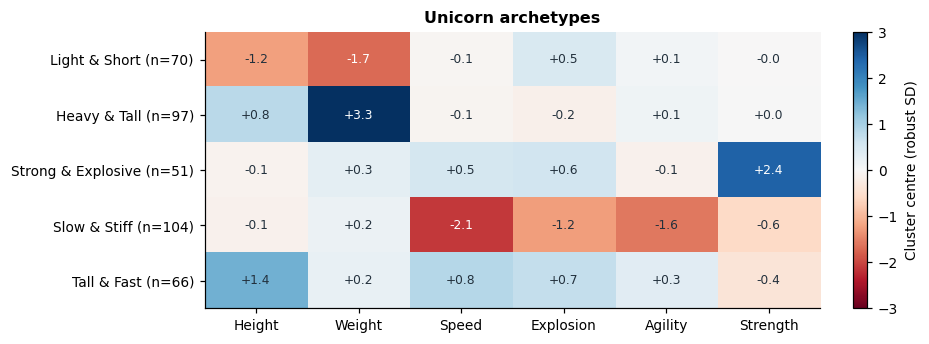

In [23]:
U = df[df.unicorn].copy()
U["speed"] = U.adj_forty
U["explosion"] = U[["adj_vertical", "adj_broad_jump"]].mean(axis=1)
U["agility"] = U[["adj_cone", "adj_shuttle"]].mean(axis=1)
U["strength"] = U.adj_bench.fillna(0)
DIMS = ["z_ht", "z_wt", "speed", "explosion", "agility", "strength"]
WORDS = {"z_ht": ("Tall", "Short"), "z_wt": ("Heavy", "Light"), "speed": ("Fast", "Slow"),
         "explosion": ("Explosive", "Grounded"), "agility": ("Agile", "Stiff"), "strength": ("Strong", "Weak")}
X_arch = U[DIMS].fillna(0).clip(-5, 5).values
silhouettes = {k: silhouette_score(X_arch, KMeans(k, n_init=25, random_state=SEED).fit_predict(X_arch)) for k in range(3, 9)}
display(pd.Series(silhouettes, name="Silhouette").round(3).to_frame().T)

K = 5
km = KMeans(K, n_init=50, random_state=SEED).fit(X_arch)
U["cluster"] = km.labels_
centres = pd.DataFrame(km.cluster_centers_, columns=DIMS)


def archetype_name(centre):
    top = centre.abs().sort_values(ascending=False).index[:2]
    return " & ".join(WORDS[d][0] if centre[d] > 0 else WORDS[d][1] for d in top)


centres["name"] = centres.apply(archetype_name, axis=1)
U["archetype"] = U.cluster.map(centres.name)
UG = U[U.grade.isin(["Bust", "Good value", "Steal"])]
archetypes = U.groupby("archetype").agg(n=("player_name", "size"), ath_z=("ath_z", "mean"),
                                        positions=("grp", lambda g: ", ".join(g.value_counts().index[:3])))
archetypes = archetypes.join(UG.groupby("archetype").agg(graded=("z", "size"), mean_z=("z", "mean"),
                                                         steal_pct=("grade", lambda g: 100 * (g == "Steal").mean()),
                                                         bust_pct=("grade", lambda g: 100 * (g == "Bust").mean())))
archetypes["examples"] = U.sort_values("av", ascending=False).groupby("archetype").player_name.apply(lambda p: ", ".join(p.head(4)))
display(archetypes.sort_values("mean_z", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(8.5, 3.2))
im = ax.imshow(centres[DIMS].values, cmap="RdBu", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(6), ["Height", "Weight", "Speed", "Explosion", "Agility", "Strength"])
ax.set_yticks(range(K), [f"{n} (n={(U.cluster == i).sum()})" for i, n in enumerate(centres.name)])
ax.grid(False)
for i in range(K):
    for j, d in enumerate(DIMS):
        v = centres.loc[i, d]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1.6 else "#22303C")
plt.colorbar(im, ax=ax, fraction=.03, label="Cluster centre (robust SD)")
ax.set_title("Unicorn archetypes")
plt.tight_layout()
plt.show()

## 9. The team view
Each franchise's unicorn picks, 2000–2022 (relocated teams folded into their current identity). Is any team
*better* at drafting unicorns than chance? We test that by **permutation**: shuffle team labels among the unicorn
picks 3,000 times and see how often the spread of team averages is as large as the real one.

,picks,freaks,steals,busts,total_voe,mean_z,best,worst,team_ath,team_z
franchise,,,,,,,,,,
SFO,10,4,3,1,90.380,0.560,"Trenton Brown (2015, #244)","Taylor Mays (2010, #49)",0.160,0.120
MIA,3,2,3,0,80.780,1.880,"Reshad Jones (2010, #163)","Paul Soliai (2007, #108)",0.150,-0.050
SEA,4,2,3,0,74.590,1.430,"Tariq Woolen (2022, #153)","Craig Terrill (2004, #189)",0.190,0.120
MIN,5,2,1,0,62.120,0.300,"Kevin Williams (2003, #9)","Carey Scott (2001, #189)",0.200,-0.000
ARI,15,4,2,2,53.040,0.090,"Calais Campbell (2008, #50)","Buster Davis (2007, #69)",0.090,-0.020
CIN,6,3,1,1,47.450,0.510,"Marvin Jones (2012, #166)","Tyler Shelvin (2021, #122)",0.230,-0.050
TEN,4,2,1,0,25.890,0.260,"Chris Johnson (2008, #24)","Terna Nande (2006, #137)",0.420,-0.080
CAR,5,2,1,1,6.690,-0.090,"Christian McCaffrey (2017, #8)","Eric Shelton (2005, #54)",0.240,0.070
JAX,5,4,0,0,4.340,0.080,"Mike Thomas (2009, #107)","Scott Starks (2005, #87)",0.260,-0.020


Permutation test: observed spread 0.53 vs 0.39 by chance; p = 0.01
Team athleticism vs team value over slot (all picks): r = 0.01, p = 0.96


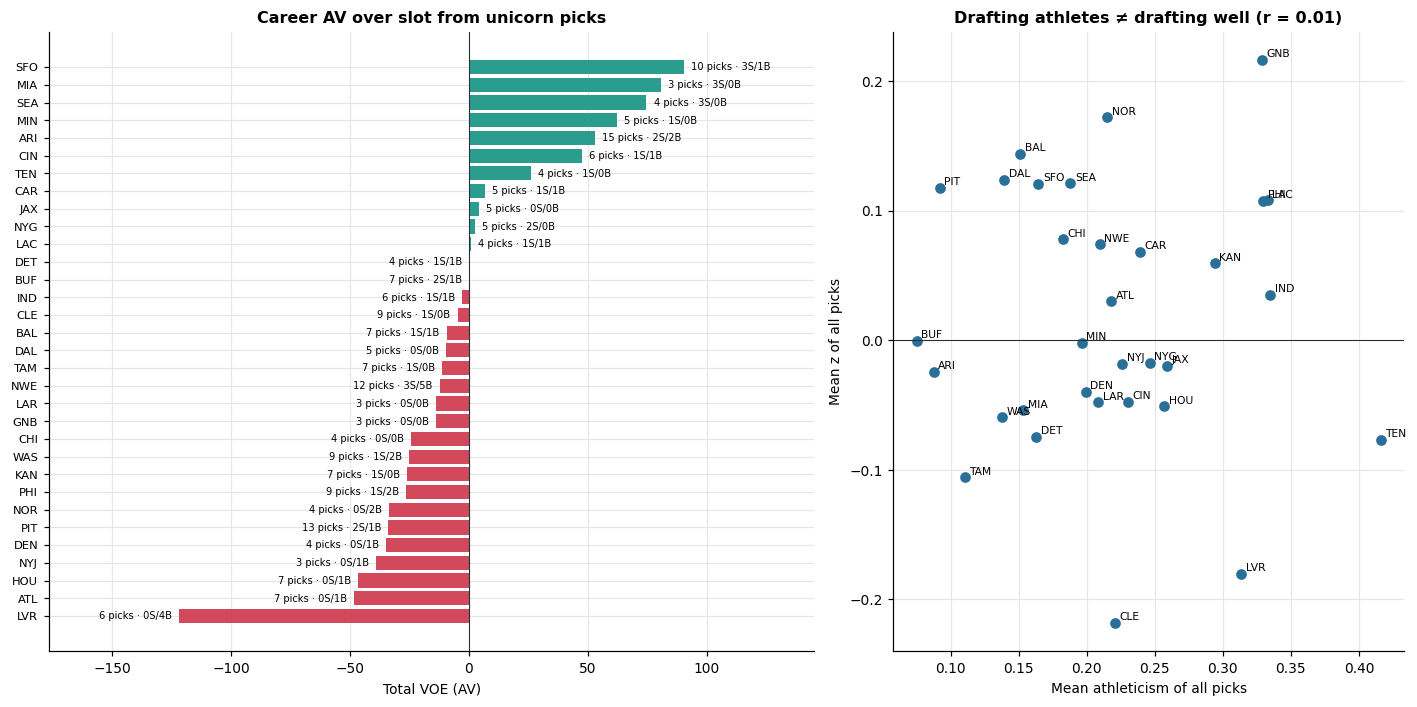

In [24]:
def best_worst(group, fn):
    r = group.loc[fn(group.z)]
    return f"{r.player_name} ({int(r.draft_year)}, #{int(r.draft_ovr)})"


teams = uni.groupby("franchise").agg(picks=("z", "size"), freaks=("utype", lambda u: (u == "Freak").sum()),
                                     steals=("grade", lambda g: (g == "Steal").sum()),
                                     busts=("grade", lambda g: (g == "Bust").sum()),
                                     total_voe=("voe", "sum"), mean_z=("z", "mean"))
teams["best"] = uni.groupby("franchise").apply(lambda g: best_worst(g, pd.Series.idxmax))
teams["worst"] = uni.groupby("franchise").apply(lambda g: best_worst(g, pd.Series.idxmin))
all_picks = graded.groupby("franchise").agg(team_ath=("ath_z", "mean"), team_z=("z", "mean"))
teams = teams.join(all_picks).sort_values("total_voe", ascending=False)
display(teams.round(2))

observed_spread = uni.groupby("franchise").z.mean().std()
shuffled = [uni.assign(f=RNG.permutation(uni.franchise.values)).groupby("f").z.mean().std() for _ in range(3000)]
perm_p = (np.array(shuffled) >= observed_spread).mean()
r_team, p_team = stats.pearsonr(teams.team_ath, teams.team_z)
print(f"Permutation test: observed spread {observed_spread:.2f} vs {np.mean(shuffled):.2f} by chance; p = {perm_p:.2f}")
print(f"Team athleticism vs team value over slot (all picks): r = {r_team:.2f}, p = {p_team:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
t_sorted = teams.sort_values("total_voe")
axes[0].barh(t_sorted.index, t_sorted.total_voe, color=np.where(t_sorted.total_voe > 0, GRADE_COLOR["Steal"], GRADE_COLOR["Bust"]))
for y, (v, n, s, b) in enumerate(zip(t_sorted.total_voe, t_sorted.picks, t_sorted.steals, t_sorted.busts)):
    axes[0].text(v + (3 if v >= 0 else -3), y, f"{n} picks · {s}S/{b}B", va="center", ha="left" if v >= 0 else "right", fontsize=6.5)
axes[0].axvline(0, color="#22303C", lw=.7)
span = t_sorted.total_voe.abs().max()
axes[0].set_xlim(t_sorted.total_voe.min() - .45 * span, t_sorted.total_voe.max() + .45 * span)
axes[0].set(title="Career AV over slot from unicorn picks", xlabel="Total VOE (AV)")
axes[0].tick_params(axis="y", labelsize=7.5)
axes[1].scatter(teams.team_ath, teams.team_z, color="#2A6F97")
for code, r in teams.iterrows():
    axes[1].annotate(code, (r.team_ath, r.team_z), xytext=(3, 2), textcoords="offset points", fontsize=7)
axes[1].axhline(0, color="#22303C", lw=.7)
axes[1].set(title=f"Drafting athletes ≠ drafting well (r = {r_team:.2f})", xlabel="Mean athleticism of all picks",
            ylabel="Mean z of all picks")
plt.tight_layout()
plt.show()

## 10. Robustness
Does the headline survive different choices? Each row redefines unicorns (holding everything else fixed) or
changes the sample, and reports the Freak, Odd build and Red flag results.

- **Threshold**: top 2%, 5% (baseline) or 10% by Mahalanobis score.
- **View**: full-workout view only, or size–speed view only.
- **χ² rule**: flag if robust D² exceeds the χ² 99.9% point in either view, instead of a fixed share.
- **Other detectors**: Isolation Forest or Local Outlier Factor on the same features and the same max-of-views rule,
  for comparison with the primary method.
- **Sample**: complete workouts only (≥5 drills), mature classes only (≤2018), no 2021 pro-day class, no Tom Brady.

Note: Tom Brady ranks at the 94.4th Mahalanobis percentile (Typical); in the paper's three-detector consensus he was a Red flag and drove that group's mean.


n                    Mean z                   
Type                          Freak Odd build Red flag  Freak Odd build Red flag
Check                                                                           
Mahalanobis top 2%               28        34       15  0.210     0.140   -0.120
Mahalanobis top 5% (baseline)    79        87       36  0.050    -0.040   -0.170
Mahalanobis top 10%             151       176       76  0.030    -0.010   -0.030
Full-workout view only, 5%       82        87       45 -0.010     0.030   -0.210
Size–speed view only, 5%         76        88       30  0.110    -0.110    0.300
χ² p < 0.001 in either view      53        50       27 -0.020     0.070   -0.290
Isolation Forest top 5%         105        57       40  0.080     0.080   -0.140
Local Outlier Factor top 5%      77        91       33  0.150     0.030    0.240
Complete workouts (≥5 drills)    52        63       26  0.180     0.010   -0.200
Mature classes (≤2018)           69        73       32  0.030     0.030   -0.160
Exclude 2021 pro-day class       75        82       34  0.070    -0.020   -0.170
Exclude Tom Brady                79        87       36  0.050    -0.040   -0.170

,Unicorns flagged,Shared with Mahalanobis,Jaccard overlap
Isolation Forest,393,224,0.400
Local Outlier Factor,391,269,0.530


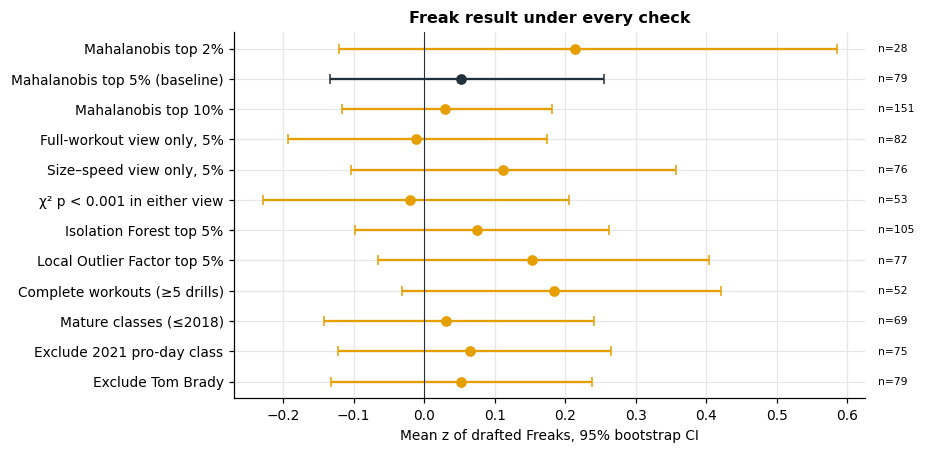

In [25]:
def other_detector_pct(make_scores):
    out = pd.Series(index=df.index, dtype=float)
    for g, group in df.groupby("grp"):
        cols = group.features.iloc[0].split(",")
        pcts = [percentile_rank(make_scores(group[c].values)) for c in (cols, ["z_ht", "z_wt", "adj_forty"])]
        out[group.index] = percentile_rank(np.maximum(*pcts))
    return out


df["if_pct"] = other_detector_pct(lambda X: -IsolationForest(n_estimators=500, random_state=SEED).fit(X).score_samples(X))
df["lof_pct"] = other_detector_pct(lambda X: -LocalOutlierFactor(n_neighbors=min(35, len(X) // 10)).fit(X).negative_outlier_factor_)
for c in ["if_pct", "lof_pct"]:
    graded[c] = graded.pid.map(df.set_index("pid")[c])

flag_rules = {
    "Mahalanobis top 2%": graded.md_pct > .98,
    "Mahalanobis top 5% (baseline)": graded.md_pct > .95,
    "Mahalanobis top 10%": graded.md_pct > .90,
    "Full-workout view only, 5%": graded.pct_full > .95,
    "Size–speed view only, 5%": graded.pct_core > .95,
    "χ² p < 0.001 in either view": (graded.chi2_p_full < .001) | (graded.chi2_p_core < .001),
    "Isolation Forest top 5%": graded.if_pct > .95,
    "Local Outlier Factor top 5%": graded.lof_pct > .95,
}
samples = {
    "Complete workouts (≥5 drills)": graded.n_drills >= 5,
    "Mature classes (≤2018)": graded.draft_year <= 2018,
    "Exclude 2021 pro-day class": graded.season != 2021,
    "Exclude Tom Brady": graded.player_name != "Tom Brady",
}
rows = []
for label, flag in flag_rules.items():
    for t, direction in [("Freak", graded.ath_z >= ATHLETIC_CUT), ("Odd build", graded.ath_z.abs() < ATHLETIC_CUT),
                         ("Red flag", graded.ath_z <= -ATHLETIC_CUT)]:
        g = graded[flag & direction]
        rows.append({"Check": label, "Type": t, "n": len(g), "Mean z": g.z.mean(),
                     "Steal %": 100 * (g.grade == "Steal").mean(), "Bust %": 100 * (g.grade == "Bust").mean(),
                     "Typical mean z": graded[~flag].z.mean()})
for label, keep in samples.items():
    g_all = graded[keep]
    for t in TYPE_ORDER[:3]:
        g = g_all[g_all.utype == t]
        rows.append({"Check": label, "Type": t, "n": len(g), "Mean z": g.z.mean(),
                     "Steal %": 100 * (g.grade == "Steal").mean(), "Bust %": 100 * (g.grade == "Bust").mean(),
                     "Typical mean z": g_all[~g_all.unicorn].z.mean()})
robust = pd.DataFrame(rows)
brady = df[(df.player_name == "Tom Brady") & (df.season == 2000)].iloc[0]
print(f"Note: Tom Brady ranks at the {100 * brady.md_pct:.1f}th Mahalanobis percentile ({brady.utype}); "
      "in the paper's three-detector consensus he was a Red flag and drove that group's mean.")
display(robust.pivot(index="Check", columns="Type", values=["n", "Mean z"])
        .reindex(list(flag_rules) + list(samples)).round(2))

overlap = pd.DataFrame({name: {"Unicorns flagged": int((df[c] > .95).sum()),
                               "Shared with Mahalanobis": int(((df[c] > .95) & df.unicorn).sum())}
                        for name, c in [("Isolation Forest", "if_pct"), ("Local Outlier Factor", "lof_pct")]}).T
overlap["Jaccard overlap"] = overlap["Shared with Mahalanobis"] / (overlap["Unicorns flagged"] + df.unicorn.sum() - overlap["Shared with Mahalanobis"])
display(overlap.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
freak_rows = robust[robust.Type == "Freak"].reset_index(drop=True)
for i, r in freak_rows.iterrows():
    mask = (flag_rules.get(r.Check, graded.unicorn) & (graded.ath_z >= ATHLETIC_CUT)) & samples.get(r.Check, True)
    z = graded[mask].z
    low, high = bootstrap_ci(z, 2000)
    ax.errorbar(z.mean(), i, xerr=[[z.mean() - low], [high - z.mean()]], fmt="o", capsize=3,
                color="#22303C" if "baseline" in r.Check else TYPE_COLOR["Freak"])
    ax.text(1.02, i, f"n={len(z)}", transform=ax.get_yaxis_transform(), fontsize=7, va="center")
ax.axvline(0, color="#22303C", lw=.7)
ax.set_yticks(range(len(freak_rows)), freak_rows.Check)
ax.invert_yaxis()
ax.set(title="Freak result under every check", xlabel="Mean z of drafted Freaks, 95% bootstrap CI")
plt.tight_layout()
plt.show()

## 11. Watch list: recent Freaks not yet gradeable
Freaks from the 2023–2026 classes. If the round-one pattern holds, the first-rounders here should bust less often
than their draft-day peers. An out-of-sample test for later.

In [26]:
watch = df[(df.utype == "Freak") & (df.season >= 2023)].sort_values(["season", "md_score"], ascending=[True, False])
display(watch[["player_name", "grp", "season", "school", "ht", "wt", "forty", "ath_z", "driver", "draft_ovr", "franchise"]].round(2))

,player_name,grp,season,school,ht,wt,forty,ath_z,driver,draft_ovr,franchise
6919,Emmanuel Forbes,CB,2023,Mississippi St.,73,166,4.350,1.320,Weight,16,WAS
6862,Adetomiwa Adebawore,EDGE,2023,Northwestern,74,282,4.490,2.320,40 speed,110,IND
7288,Nate Wiggins,CB,2024,Clemson,73,173,4.280,0.970,Weight,30,BAL
7298,Xavier Worthy,WR,2024,Texas,71,165,4.210,2.170,Weight,28,KAN
7396,Tez Johnson,WR,2025,Oregon,70,154,4.510,0.880,Weight,235,TAM
7446,Darien Porter,CB,2025,Iowa St.,75,195,4.300,1.300,Height,68,LVR
7522,Deion Burks,WR,2026,Oklahoma,70,180,4.300,2.920,Bench,254,IND
7559,Taylen Green,QB,2026,Arkansas,78,227,4.360,3.150,Vertical,182,CLE
7643,Kadyn Proctor,OT,2026,Alabama,79,352,5.210,1.110,Weight,12,MIA


## 12. Summary of findings
Detection. Robust Mahalanobis distance flags 388 unicorns among 7,690 prospects: 99 Freaks, 151 Odd builds and 138 Red flags.

Price. Freaks are drafted 89% of the time vs 66% for typical prospects, at a median pick of 68 vs 108.

Return. Graded Freaks (n=79) average z = +0.05 [95% CI -0.13, +0.25] vs +0.02 for typical players (Welch p = 0.73). Bust 14% vs 14%; steal 20% vs 17%.
Round 1. First-round Freaks (n=24) average z = +0.27, bust 12% vs 23% for other first-rounders.

Better vs different. With controls, each SD of athleticism adds +0.037 SD of slot value (p = 0.039); Mahalanobis rarity adds +0.062 (p = 0.24).
Teams. Team results differ more than chance would produce (permutation p = 0.01), but most teams have only a handful of unicorn picks, so a few players drive the ranking.

## 13. Save outputs to Drive
Tables go to `Pricing the Unicorn/milestone2_outputs` so they survive after the Colab session ends.

In [28]:
export_cols = ["player_name", "season", "pos", "grp", "school", "ht", "wt"] + DRILLS + \
              ["ath_z", "d2_full", "d2_core", "md_pct", "driver", "utype", "draft_year", "draft_round", "draft_ovr",
               "franchise", "av", "exp_av", "voe", "z", "grade"]
df[df.unicorn].sort_values(["grp", "md_pct"], ascending=[True, False])[export_cols].to_csv(OUT / "unicorns_mahalanobis.csv", index=False)
df[export_cols].to_csv(OUT / "all_prospects_scored.csv", index=False)
value_table.to_csv(OUT / "value_by_type.csv")
regressions.to_csv(OUT / "regressions.csv")
by_round.to_csv(OUT / "value_by_round.csv", index=False)
teams.to_csv(OUT / "teams.csv")
archetypes.to_csv(OUT / "archetypes.csv")
robust.to_csv(OUT / "robustness.csv", index=False)
print("Saved:", ", ".join(sorted(p.name for p in OUT.glob("*.csv"))))

Saved: all_prospects_scored.csv, archetypes.csv, regressions.csv, robustness.csv, teams.csv, unicorns_mahalanobis.csv, value_by_round.csv, value_by_type.csv
